# Student outcome analysis


## Setup


In [51]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
DATA_PATH = Path("data.csv")
pd.set_option("display.max_columns", 40)

## 1. Problem framing

We investigate how early a student's academic outcome (Graduate, Dropout, or Enrolled) can be predicted using information available at enrolment, after the first semester, and after the second semester.

Early predictions could help educators identify students at risk and direct support where it is most needed, while differences in outcomes across student groups can highlight potential barriers to academic success.

We use macro F1 to tune and compare models against a majority-class baseline, and dropout recall to assess their ability to identify students who eventually drop out.

## 2. Data acquisition & understanding

### 2.1 Source

We use the [Predict Students’ Dropout and Academic Success dataset (UCI #697)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), containing undergraduate student records from the Polytechnic Institute of Portalegre in Portugal from 2008/2009 to 2018/2019. The dataset is available under a CC BY 4.0 licence.

### 2.2 Structure and size

The dataset contains 4,424 student records, with 36 input features and one target variable.


In [52]:
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

assert df.shape == (4424, 37), df.shape
assert set(df["Target"]) == {"Dropout", "Enrolled", "Graduate"}

print(df.shape)
df.head()


(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### 2.3 Fields

| Feature group | Type | Fields |
|---|---|---|
| Demographics | Categorical | Marital status, nationality, gender, international status |
| Demographics | Numerical | Age at enrolment |
| Application and admission | Categorical | Application mode, course, daytime/evening attendance, previous qualification |
| Application and admission | Numerical | Application order, previous qualification grade, admission grade |
| Family background | Categorical | Mother's qualification, father's qualification, mother's occupation, father's occupation |
| Socioeconomic factors | Categorical | Displaced status, educational special needs, debtor status, tuition payment status, scholarship status |
| Semester performance | Numerical | Credited units, enrolled units, assessments, approved units, average grade, units without evaluations (per semester) |
| Macroeconomic indicators | Numerical | Unemployment rate, inflation rate, GDP |
| Target | Categorical | Academic outcome (Graduate, Dropout, Enrolled) |

The dataset contains 17 categorical and 19 numerical input features. The target records the student's academic outcome at the end of the program's expected duration.

Previous qualification and admission grades use a 0–200 scale, while semester average grades use a 0–20 scale. A curricular unit can have multiple assessments.

### 2.4 Limitations

- Records originate from a single institution.
- Financial, demographic, and family circumstances are represented by limited attributes.
- Macroeconomic indicators describe national conditions at enrolment rather than individual circumstances.
- Semester performance is aggregated rather than recorded for individual curricular units.
- Student identifiers, reasons for dropout, and subsequent academic outcomes are unavailable.


## 3. Cleaning & preparation

We check for missing values, duplicates, inconsistencies, and outliers, retaining unusual values when they are plausible or a reliable correction is unavailable.


### 3.1 Missing values

The original dataset contains no missing values. Codes representing unknown parental qualifications (34), blank occupations (99), and other occupational situations (90) are retained as documented categories.


In [53]:
missing = df.isna().sum()
print("missing cells:", int(missing.sum()))
print("columns with a missing cell:", int((missing > 0).sum()))

recorded = pd.Series(
    {
        "Mother's qualification = 34 (Unknown)": int((df["Mother's qualification"] == 34).sum()),
        "Father's qualification = 34 (Unknown)": int((df["Father's qualification"] == 34).sum()),
        "Mother's occupation = 90 (Other Situation)": int((df["Mother's occupation"] == 90).sum()),
        "Mother's occupation = 99 (blank)": int((df["Mother's occupation"] == 99).sum()),
        "Father's occupation = 90 (Other Situation)": int((df["Father's occupation"] == 90).sum()),
        "Father's occupation = 99 (blank)": int((df["Father's occupation"] == 99).sum()),
    }
)
print(recorded.to_string())


missing cells: 0
columns with a missing cell: 0
Mother's qualification = 34 (Unknown)         130
Father's qualification = 34 (Unknown)         112
Mother's occupation = 90 (Other Situation)     70
Mother's occupation = 99 (blank)               17
Father's occupation = 90 (Other Situation)     65
Father's occupation = 99 (blank)               19


All 12 curricular-unit fields are zero for 180 students in Animation and Multimedia Design (course 171). Since 75 of these students graduated, the zeros likely represent missing records. We replace these values with missing entries and retain zeros elsewhere.


In [54]:
curricular = [col for col in df.columns if col.startswith("Curricular units")]
all_zero = df[curricular].sum(axis=1) == 0
course = int(df.loc[all_zero, "Course"].iloc[0])
print("curricular fields all zero:", int(all_zero.sum()))
print("course:", course)
print("students in that course:", int((df["Course"] == course).sum()))
print(df.loc[all_zero, "Target"].value_counts().to_string())
df.loc[all_zero, curricular] = pd.NA
print("curricular fields missing:", int(df[curricular].isna().all(axis=1).sum()))


curricular fields all zero: 180
course: 171
students in that course: 215
Target
Dropout     77
Graduate    75
Enrolled    28
curricular fields missing: 180


### 3.2 Duplication

All 4,424 rows are unique, even when any single column is excluded. No rows are removed. Since student identifiers are unavailable, duplication checks are limited to the recorded attributes.


In [55]:
features = [col for col in df.columns if col != "Target"]
print("exact duplicate rows:", int(df.duplicated().sum()))
print("duplicate inputs:", int(df.duplicated(subset=features).sum()))

dropped_one = 0
for col in df.columns:
    others = [name for name in df.columns if name != col]
    dropped_one += int(df.duplicated(subset=others).sum())
print("duplicate rows after dropping one column:", dropped_one)


exact duplicate rows: 0
duplicate inputs: 0
duplicate rows after dropping one column: 0


### 3.3 Inconsistent values/formats

`Target` contains only Dropout, Enrolled, and Graduate, and each binary field contains only 0 or 1.


In [56]:
binary_cols = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
print(sorted(df["Target"].unique()))
for col in binary_cols:
    print(col, sorted(df[col].unique().tolist()))


['Dropout', 'Enrolled', 'Graduate']
Daytime/evening attendance [0, 1]
Displaced [0, 1]
Educational special needs [0, 1]
Debtor [0, 1]
Tuition fees up to date [0, 1]
Gender [0, 1]
Scholarship holder [0, 1]
International [0, 1]


The data dictionary distinguishes bachelor's degrees (2), degrees (3), and first-cycle degrees (40), as well as different codes for master's qualifications (4 and 43) and doctorates (5 and 44). These categories are retained as recorded.


In [57]:
pairs = [
    ("bachelor's", "Mother's qualification", 2, 40),
    ("bachelor's", "Father's qualification", 2, 40),
    ("bachelor's", "Previous qualification", 2, 40),
    ("degree", "Mother's qualification", 3, 40),
    ("degree", "Father's qualification", 3, 40),
    ("degree", "Previous qualification", 3, 40),
    ("master's", "Mother's qualification", 4, 43),
    ("master's", "Father's qualification", 4, 43),
    ("master's", "Previous qualification", 4, 43),
    ("doctorate", "Mother's qualification", 5, 44),
    ("doctorate", "Father's qualification", 5, 44),
    ("doctorate", "Previous qualification", 5, 44),
]
for level, col, older, later in pairs:
    print(
        f"{col} | {level}: {older} -> {int((df[col] == older).sum())}, "
        f"{later} -> {int((df[col] == later).sum())}"
    )


Mother's qualification | bachelor's: 2 -> 83, 40 -> 9
Father's qualification | bachelor's: 2 -> 68, 40 -> 5
Previous qualification | bachelor's: 2 -> 23, 40 -> 40
Mother's qualification | degree: 3 -> 438, 40 -> 9
Father's qualification | degree: 3 -> 282, 40 -> 5
Previous qualification | degree: 3 -> 126, 40 -> 40
Mother's qualification | master's: 4 -> 49, 43 -> 4
Father's qualification | master's: 4 -> 39, 43 -> 2
Previous qualification | master's: 4 -> 8, 43 -> 6
Mother's qualification | doctorate: 5 -> 21, 44 -> 1
Father's qualification | doctorate: 5 -> 18, 44 -> 1
Previous qualification | doctorate: 5 -> 1, 44 -> 0


`Mother's qualification` and `Father's qualification` distinguish the 7th year (old), code 11, from the 7th year of schooling, code 26. Both codes are retained.


In [58]:
for col in ["Mother's qualification", "Father's qualification"]:
    print(f"{col}: 11 -> {int((df[col] == 11).sum())}, 26 -> {int((df[col] == 26).sum())}")


Mother's qualification: 11 -> 3, 26 -> 1
Father's qualification: 11 -> 10, 26 -> 2


`Course` distinguishes daytime and evening offerings of Social Service (9238 and 8014) and Management (9147 and 9991). The attendance field agrees with these codes, so they are retained.


In [59]:
courses = [
    (9238, "Social Service"),
    (8014, "Social Service (evening)"),
    (9147, "Management"),
    (9991, "Management (evening)"),
]
for code, name in courses:
    rows = df[df["Course"] == code]
    counts = rows["Daytime/evening attendance"].value_counts().sort_index()
    print(f"{code} {name}: {len(rows)} students, attendance {counts.to_dict()}")


9238 Social Service: 355 students, attendance {1: 355}
8014 Social Service (evening): 215 students, attendance {0: 215}
9147 Management: 380 students, attendance {1: 380}
9991 Management (evening): 268 students, attendance {0: 268}


### 3.4 Stray characters in names

`Daytime/evening attendance` has a trailing tab in the original file. Stripping whitespace from column names in Section 2 removes it without changing the values.


In [60]:
raw_names = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig", nrows=0).columns
trailing = [name for name in raw_names if name != name.strip()]
print(repr(trailing[0]))
print("Daytime/evening attendance" in df.columns)


'Daytime/evening attendance\t'
True


### 3.5 Impossible values

No impossible values are identified. Ages at enrolment fall within 17–70, admission and previous qualification grades within 0–200, and curricular grades within 0–20. Recorded unit counts are non-negative.


In [61]:
age_bad = ~df["Age at enrollment"].between(17, 70)
grade_bad = ~df["Admission grade"].between(0, 200)
grade_bad = grade_bad | ~df["Previous qualification (grade)"].between(0, 200)
curricular = [col for col in df.columns if col.endswith("(grade)") and "sem" in col]
grade_bad = grade_bad | (df[curricular].lt(0) | df[curricular].gt(20)).any(axis=1)
counts = [col for col in df.columns if "Curricular units" in col and "(grade)" not in col]
count_bad = df[counts].lt(0).any(axis=1)
print(int((age_bad | grade_bad | count_bad).sum()))


0


### 3.6 Contradictions between columns

Three students have more second-semester units without evaluations than units enrolled (12 versus 6, 7 versus 6, and 8 versus 5). We retain the records because the correct counts cannot be determined.


In [62]:
enrolled = "Curricular units 2nd sem (enrolled)"
without = "Curricular units 2nd sem (without evaluations)"
print(
    df.loc[
        df[without] > df[enrolled],
        [enrolled, without, "Target"],
    ].to_string()
)


      Curricular units 2nd sem (enrolled)  Curricular units 2nd sem (without evaluations)   Target
533                                   6.0                                            12.0  Dropout
1378                                  6.0                                             7.0  Dropout
2931                                  5.0                                             8.0  Dropout


Approved units plus units without evaluations exceed enrolled units in 86 first-semester and 92 second-semester records, including the three cases above. We retain the values because the semester totals provide no reliable basis for correction.


In [63]:
for sem in ("1st sem", "2nd sem"):
    enrolled = df[f"Curricular units {sem} (enrolled)"]
    approved = df[f"Curricular units {sem} (approved)"]
    without = df[f"Curricular units {sem} (without evaluations)"]
    over = (approved + without) - enrolled
    over = over[over > 0]
    print(f"{sem}: {len(over)} rows, excess {over.value_counts().sort_index().to_dict()}")


1st sem: 86 rows, excess {1.0: 52, 2.0: 28, 3.0: 1, 4.0: 1, 6.0: 1, 9.0: 1, 10.0: 1, 12.0: 1}
2nd sem: 92 rows, excess {1.0: 58, 2.0: 13, 3.0: 9, 4.0: 2, 5.0: 7, 6.0: 2, 9.0: 1}


### 3.7 Outliers

One student enrolled at age 70. We retain the record because enrolment at this age is plausible.

Inflation is negative for 923 students, and GDP growth is negative for 1,711. These values reflect economic conditions in the enrolment years and are retained.


In [64]:
print("age 70:", int((df["Age at enrollment"] == 70).sum()))
print("negative inflation:", int((df["Inflation rate"] < 0).sum()))
print("negative GDP:", int((df["GDP"] < 0).sum()))


age 70: 1
negative inflation: 923
negative GDP: 1711


One student enrolled at age 18 with a recorded master's qualification (code 4). We retain both values because there is no reliable basis for correcting either.


In [65]:
young_master = (
    (df["Age at enrollment"] == 18)
    & (df["Previous qualification"] == 4)
)

display(df.loc[
    young_master,
    [
        "Age at enrollment",
        "Previous qualification",
        "Previous qualification (grade)",
        "Course",
        "Target",
    ],
].T)

,4255
Age at enrollment,18
Previous qualification,4
Previous qualification (grade),120.0
Course,8014
Target,Dropout


### 3.8 Joins and merges

No joins or merges are required because the published CSV already combines the source records into a single table.


In [66]:
print(DATA_PATH.name, df.shape)


data.csv (4424, 37)


## 4. Exploratory data analysis

We explore patterns that inform the staged models and differences across student groups that warrant further investigation. The figures describe associations, not causal relationships.

### 4.1 Outcome distribution

**Students by outcome**

The bar chart shows the count and percentage of students in each outcome class.

Graduate: 2209 (49.9%)
Dropout: 1421 (32.1%)
Enrolled: 794 (17.9%)


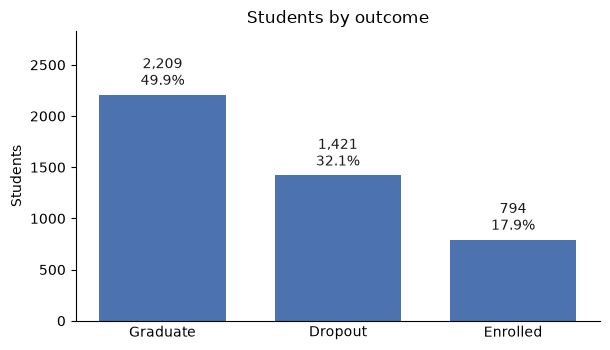

In [67]:
order = ["Graduate", "Dropout", "Enrolled"]
counts = df["Target"].value_counts().reindex(order)
shares = counts / counts.sum() * 100
for name in order:
    print(f"{name}: {int(counts[name])} ({shares[name]:.1f}%)")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
bars = ax.bar(order, counts.to_numpy(), color="#4C72B0", width=0.72)
ax.set_ylabel("Students")
ax.set_xlabel("")
ax.set_title("Students by outcome")
for bar, name in zip(bars, order):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 50,
        f"{int(height):,}\n{shares[name]:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#1A1A1A",
    )
ax.set_ylim(0, counts.max() * 1.28)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0)
fig.tight_layout()
plt.show()


Of the 4,424 students, 2,209 graduated (49.9%), 1,421 dropped out (32.1%), and 794 remained enrolled (17.9%). Macro F1 gives each outcome equal weight despite these differences in class size.

### 4.2 Patterns that inform modelling

**Numeric fields by outcome**

The box plots compare five numeric fields across outcomes for the 4,244 students with recorded semester data.

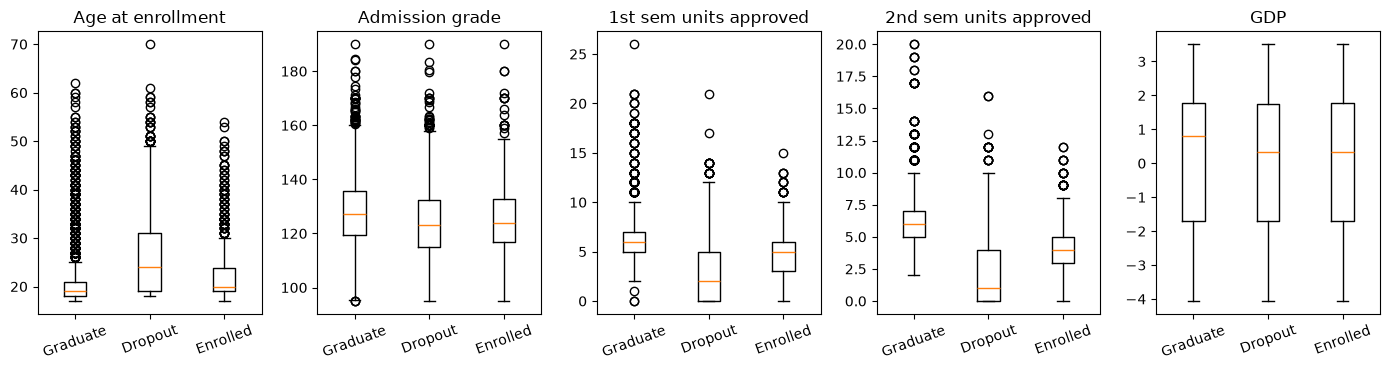

In [68]:
order = ["Graduate", "Dropout", "Enrolled"]
fields = [
    ("Age at enrollment", "Age at enrollment"),
    ("Admission grade", "Admission grade"),
    ("Curricular units 1st sem (approved)", "1st sem units approved"),
    ("Curricular units 2nd sem (approved)", "2nd sem units approved"),
    ("GDP", "GDP"),
]
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
fig, axes = plt.subplots(1, len(fields), figsize=(14, 3.8))
for ax, (col, title) in zip(axes, fields):
    groups = [plot_df.loc[plot_df["Target"] == name, col] for name in order]
    ax.boxplot(groups)
    ax.set_xticks([1, 2, 3], order, rotation=20)
    ax.set_title(title)
fig.tight_layout()
plt.show()


Graduates passed a median of six units in each semester, compared with two and one for dropouts and five and four for students still enrolled. Median age at enrolment was 24 for dropouts, 19 for graduates, and 20 for those still enrolled. Admission grade and GDP overlap across outcomes. The first-semester gap motivates comparing enrolment-only models with models that include first-semester results.

**Mean values by outcome**

The following table summarizes selected numeric fields using available values for each field.

In [69]:
summary_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
]
df.groupby("Target")[summary_cols].mean().round(2)


,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
Target,,,,,
Dropout,26.07,124.96,2.70,2.05,6.24
Enrolled,22.37,125.53,4.48,4.21,11.52
Graduate,21.78,128.79,6.45,6.39,13.14


**Approved units across semesters**

The scatter plot compares approved units in the first and second semesters for the 4,244 students with recorded semester data. The grey diagonal marks equal counts.

correlation: 0.89
equal: 2239 of 4244
first semester higher: 1180
second semester higher: 825


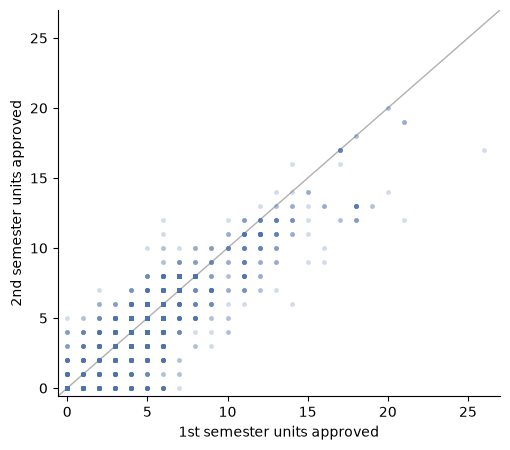

In [70]:
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
first = plot_df["Curricular units 1st sem (approved)"]
second = plot_df["Curricular units 2nd sem (approved)"]
print(f"correlation: {first.corr(second):.2f}")
print(f"equal: {int((first == second).sum())} of {len(plot_df)}")
print(f"first semester higher: {int((first > second).sum())}")
print(f"second semester higher: {int((second > first).sum())}")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([-0.6, 27], [-0.6, 27], color="#B0B0B0", linewidth=1, zorder=0)
ax.scatter(first, second, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
ax.set_xlim(-0.6, 27)
ax.set_ylim(-0.6, 27)
ax.set_xlabel("1st semester units approved")
ax.set_ylabel("2nd semester units approved")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


The counts are strongly correlated (r = 0.89). They are equal for 2,239 students, higher in the first semester for 1,180, and higher in the second for 825. This motivates evaluating how much second-semester results add beyond the first semester.

**Approved units and semester grades**

The scatter plots compare approved units with average grade for each semester, using the same 4,244 students.

1st sem correlation: 0.65
1st sem correlation, at least one unit approved: 0.26
1st sem approved is 0: 538, and grade is 0 for all of them
2nd sem correlation: 0.73
2nd sem correlation, at least one unit approved: 0.33
2nd sem approved is 0: 690, and grade is 0 for all of them


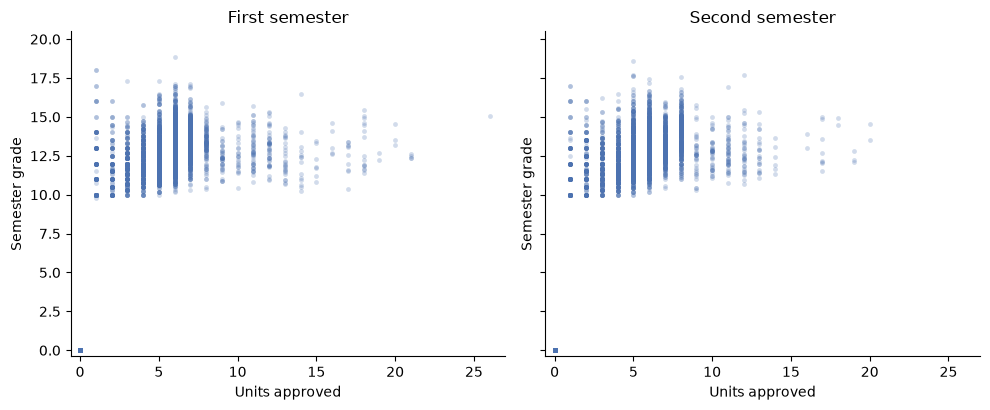

In [71]:
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
semesters = [("1st sem", "First semester"), ("2nd sem", "Second semester")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, (sem, title) in zip(axes, semesters):
    approved = plot_df[f"Curricular units {sem} (approved)"]
    grade = plot_df[f"Curricular units {sem} (grade)"]
    passed = approved > 0
    print(f"{sem} correlation: {approved.corr(grade):.2f}")
    print(f"{sem} correlation, at least one unit approved: {approved[passed].corr(grade[passed]):.2f}")
    print(f"{sem} approved is 0: {int((~passed).sum())}, and grade is 0 for all of them")
    ax.scatter(approved, grade, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
    ax.set_title(title)
    ax.set_xlabel("Units approved")
    ax.set_ylabel("Semester grade")
    ax.set_xlim(-0.6, 27)
    ax.set_ylim(-0.4, 20.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


Correlations are 0.65 and 0.73 for the first and second semesters. All 538 and 690 students, respectively, who passed no units received a grade of zero. Among students who passed at least one unit, correlations fall to 0.26 and 0.33, with median grades of 12.6 and 12.7.

**Previous qualification and admission grades**

The scatter plot compares the two grades for all 4,424 students. The diagonal marks equal grades.

correlation: 0.58
equal: 484 of 4424
median admission minus previous: -5.2


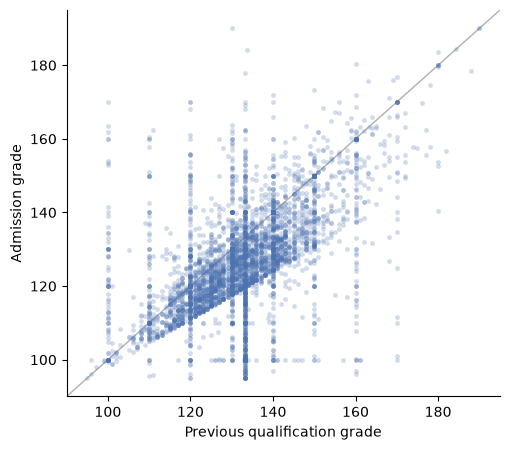

In [72]:
prev = df["Previous qualification (grade)"]
adm = df["Admission grade"]
print(f"correlation: {prev.corr(adm):.2f}")
print(f"equal: {int((prev == adm).sum())} of {len(df)}")
print(f"median admission minus previous: {(adm - prev).median():.1f}")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([90, 195], [90, 195], color="#B0B0B0", linewidth=1, zorder=0)
ax.scatter(prev, adm, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
ax.set_xlim(90, 195)
ax.set_ylim(90, 195)
ax.set_xlabel("Previous qualification grade")
ax.set_ylabel("Admission grade")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


The correlation is 0.58; the grades are equal for 484 students. The median difference (admission minus previous qualification grade) is −5.2 points.

### 4.3 Outcome differences and equity

**Outcomes by student group**

The stacked bars show outcome percentages within six binary student groups, with group sizes on the axes.

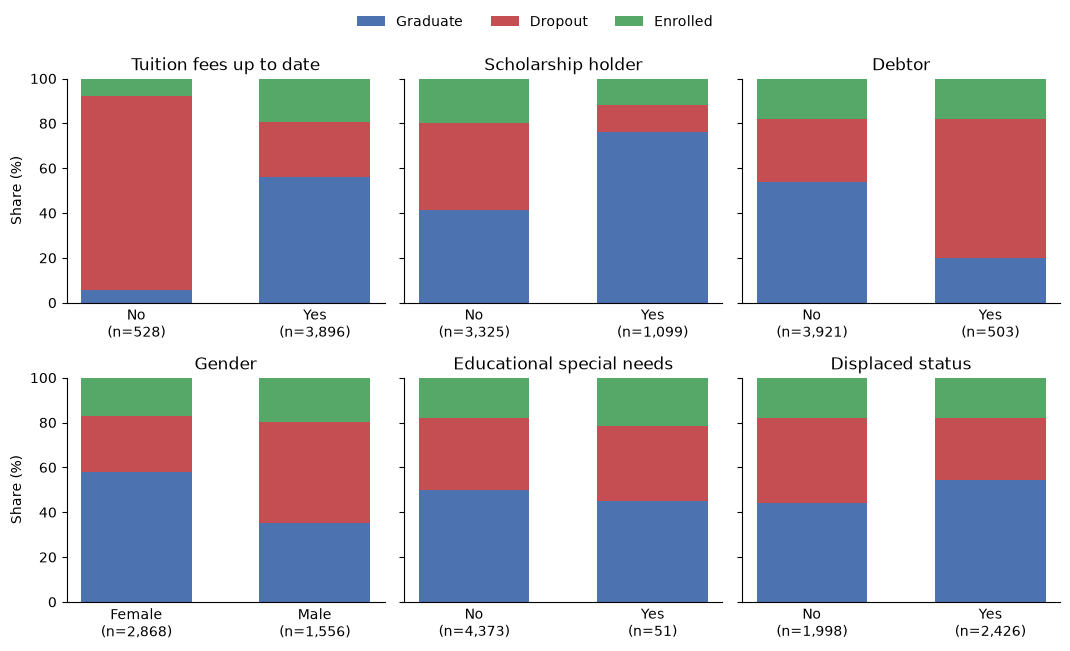

In [73]:
order = ["Graduate", "Dropout", "Enrolled"]
colors = {"Graduate": "#4C72B0", "Dropout": "#C44E52", "Enrolled": "#55A868"}
fields = [
    ("Tuition fees up to date", {0: "No", 1: "Yes"}),
    ("Scholarship holder", {0: "No", 1: "Yes"}),
    ("Debtor", {0: "No", 1: "Yes"}),
    ("Gender", {0: "Female", 1: "Male"}),
    ("Educational special needs", {0: "No", 1: "Yes"}),
    ("Displaced", {0: "No", 1: "Yes"}),
]
fig, axes = plt.subplots(2, 3, figsize=(10.8, 6.6), sharey=True)
for ax, (col, labels) in zip(axes.ravel(), fields):
    counts = pd.crosstab(df[col], df["Target"]).reindex(columns=order)
    shares = counts.div(counts.sum(axis=1), axis=0) * 100
    bottom = None
    x = list(range(len(shares.index)))
    for name in order:
        heights = shares[name].to_numpy()
        ax.bar(
            x,
            heights,
            bottom=0 if bottom is None else bottom,
            color=colors[name],
            width=0.62,
            label=name,
        )
        bottom = heights if bottom is None else bottom + heights
    tick_labels = [
        f"{labels[code]}\n(n={int(counts.loc[code].sum()):,})" for code in shares.index
    ]
    ax.set_xticks(x, tick_labels)
    ax.set_ylim(0, 100)
    ax.set_title("Displaced status" if col == "Displaced" else col)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)
for ax in axes[:, 0]:
    ax.set_ylabel("Share (%)")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.99),
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


Dropout rates are 86.6% for students whose fees are not up to date versus 24.7% for those whose fees are up to date; 62.0% for debtors versus 28.3% for other students; and 38.7% for students without scholarships versus 12.2% for scholarship holders. These associations motivate the restricted Stage A experiment in Section 6.4.

Dropout rates are 45.1% for male students and 25.1% for female students. Rates are 33.3% for students with recorded educational special needs (17 of 51) versus 32.1% for other students; the smaller group gives a less precise estimate. Rates are 27.6% for displaced students versus 37.6% for non-displaced students.

**Outcomes by course**

Each bar shows outcome percentages within a course, along with its enrolment count.

Target  Graduate  Dropout  Enrolled    n
Course                                  
33           8.3     66.7      25.0   12
9130        29.8     55.3      14.9  141
9119         8.2     54.1      37.6  170
9991        29.1     50.7      20.1  268
9853        29.7     44.3      26.0  192
9003        41.4     41.0      17.6  210
9556        41.9     38.4      19.8   86
171         44.7     38.1      17.2  215
9254        45.6     38.1      16.3  252
9670        46.6     35.4      17.9  268
9147        36.3     35.3      28.4  380
8014        57.2     33.0       9.8  215
9773        59.2     30.5      10.3  331
9085        51.0     26.7      22.3  337
9070        58.8     22.6      18.6  226
9238        69.9     18.3      11.8  355
9500        71.5     15.4      13.1  766


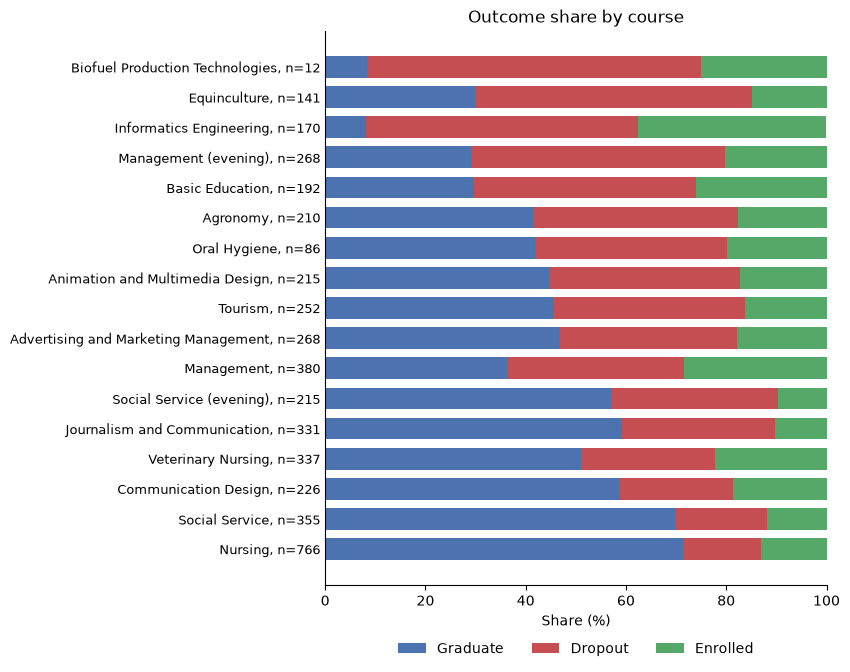

In [74]:
order = ["Graduate", "Dropout", "Enrolled"]
colors = {"Graduate": "#4C72B0", "Dropout": "#C44E52", "Enrolled": "#55A868"}
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
counts = pd.crosstab(df["Course"], df["Target"]).reindex(columns=order)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[order].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values("Dropout", ascending=False)
print(shares.round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for name in order:
    ax.barh(y, shares[name], left=left, color=colors[name], label=name, height=0.72)
    left = left + shares[name]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Outcome share by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Among courses with more than 100 students, Equinculture has the highest dropout rate (55.3% of 141 students) and Nursing the lowest (15.4% of 766). In Informatics Engineering, 54.1% of 170 students dropped out and 8.2% graduated. Rates for small courses such as Biofuel Production Technologies (12 students) are sensitive to individual outcomes.

**Gender by course**

The bars compare gender composition across courses.

male: 1556 (35.2%)
Gender  Male  Female    n
Course                   
9119    95.9     4.1  170
33      75.0    25.0   12
9003    71.0    29.0  210
171     54.4    45.6  215
9991    50.7    49.3  268
9670    45.5    54.5  268
9130    44.0    56.0  141
9147    42.6    57.4  380
9070    42.5    57.5  226
9254    39.7    60.3  252
9773    34.7    65.3  331
9556    22.1    77.9   86
8014    19.5    80.5  215
9500    19.5    80.5  766
9085    17.8    82.2  337
9238    13.0    87.0  355
9853     4.7    95.3  192


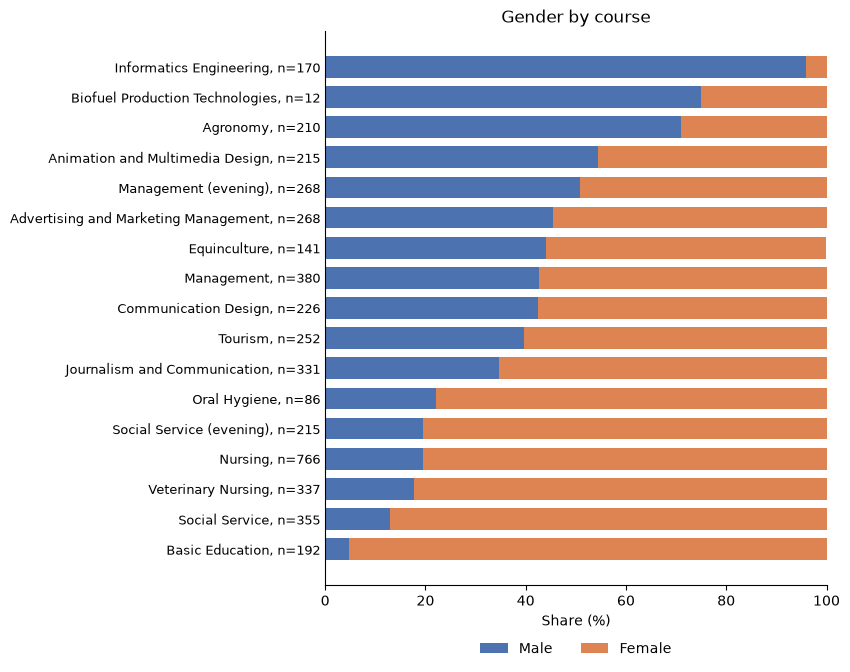

In [75]:
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
levels = [1, 0]
level_names = {1: "Male", 0: "Female"}
colors = {1: "#4C72B0", 0: "#DD8452"}
counts = pd.crosstab(df["Course"], df["Gender"]).reindex(columns=levels)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[levels].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values(1, ascending=False)
print(f"male: {int((df['Gender'] == 1).sum())} ({(df['Gender'] == 1).mean() * 100:.1f}%)")
print(shares.rename(columns=level_names).round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for code in levels:
    ax.barh(y, shares[code], left=left, color=colors[code], label=level_names[code], height=0.72)
    left = left + shares[code]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Gender by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Male students make up 35.2% of the dataset. The share is 95.9% in Informatics Engineering, 71.0% in Agronomy, 19.5% in Nursing, 13.0% in Social Service, and 4.7% in Basic Education. Differences in course composition are relevant when interpreting the overall dropout gap by gender.

**Scholarship by course**

The bars compare scholarship status across courses.

scholarship holders: 1099 (24.8%)
Scholarship holder   Yes     No    n
Course                              
9238                38.9   61.1  355
9500                36.3   63.7  766
9773                31.4   68.6  331
9556                31.4   68.6   86
9070                31.0   69.0  226
9254                28.2   71.8  252
9670                25.7   74.3  268
171                 24.2   75.8  215
9853                20.8   79.2  192
9147                20.3   79.7  380
8014                20.0   80.0  215
9085                16.6   83.4  337
9119                11.8   88.2  170
9003                 9.5   90.5  210
9130                 9.2   90.8  141
9991                 7.8   92.2  268
33                   0.0  100.0   12


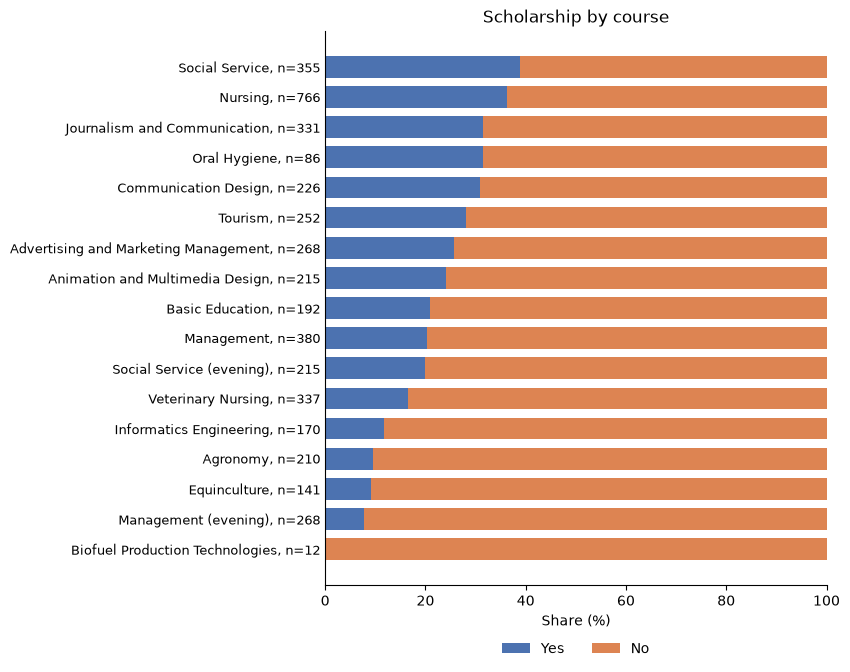

In [76]:
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
levels = [1, 0]
level_names = {1: "Yes", 0: "No"}
colors = {1: "#4C72B0", 0: "#DD8452"}
counts = pd.crosstab(df["Course"], df["Scholarship holder"]).reindex(columns=levels)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[levels].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values(1, ascending=False)
holders = int((df["Scholarship holder"] == 1).sum())
print(f"scholarship holders: {holders} ({holders / len(df) * 100:.1f}%)")
print(shares.rename(columns=level_names).round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for code in levels:
    ax.barh(y, shares[code], left=left, color=colors[code], label=level_names[code], height=0.72)
    left = left + shares[code]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Scholarship by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Scholarship holders make up 24.8% of students. The share is 38.9% in Social Service and 36.3% in Nursing, compared with 7.8% in evening Management, 9.2% in Equinculture, and 9.5% in Agronomy. Small course sizes should be considered when interpreting these percentages.

### 4.4 Additional exploratory analysis

**Parents’ qualifications**

The heatmap shows the distribution of fathers’ qualifications within mothers’ qualification categories, restricted to codes with at least 50 observations for each parent.

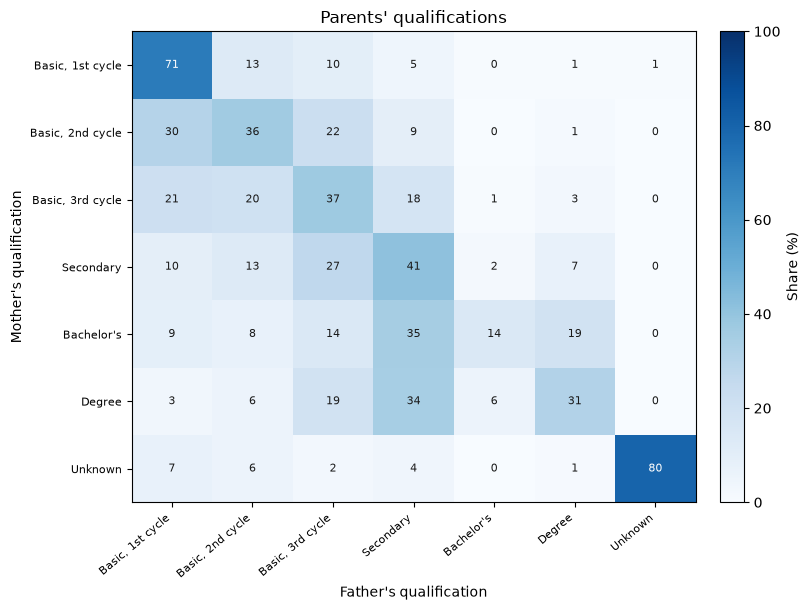

In [77]:
order = [37, 38, 19, 1, 2, 3, 34]
labels = {
    37: "Basic, 1st cycle",
    38: "Basic, 2nd cycle",
    19: "Basic, 3rd cycle",
    1: "Secondary",
    2: "Bachelor's",
    3: "Degree",
    34: "Unknown",
}
mother = "Mother's qualification"
father = "Father's qualification"
keep = [code for code in order if (df[mother] == code).sum() >= 50 and (df[father] == code).sum() >= 50]
sub = df[df[mother].isin(keep) & df[father].isin(keep)]
shares = pd.crosstab(sub[mother], sub[father], normalize="index").reindex(index=keep, columns=keep) * 100
same = int((sub[mother] == sub[father]).sum())
fig, ax = plt.subplots(figsize=(8.2, 6.2))
image = ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(keep)), [labels[code] for code in keep], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(keep)), [labels[code] for code in keep], fontsize=8)
ax.set_xlabel("Father's qualification")
ax.set_ylabel("Mother's qualification")
ax.set_title("Parents' qualifications")
for i in range(len(keep)):
    for j in range(len(keep)):
        value = shares.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value >= 55 else "#1A1A1A",
        )
fig.colorbar(image, ax=ax, label="Share (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


Among the 4,131 students included, 1,919 (46.5%) have parents with the same qualification code. The strongest matches are basic education, first cycle (71%), and unknown (80%).

**Parents’ occupations**

The heatmap uses the same conditional-share approach for occupation codes with at least 50 observations for the corresponding parent.

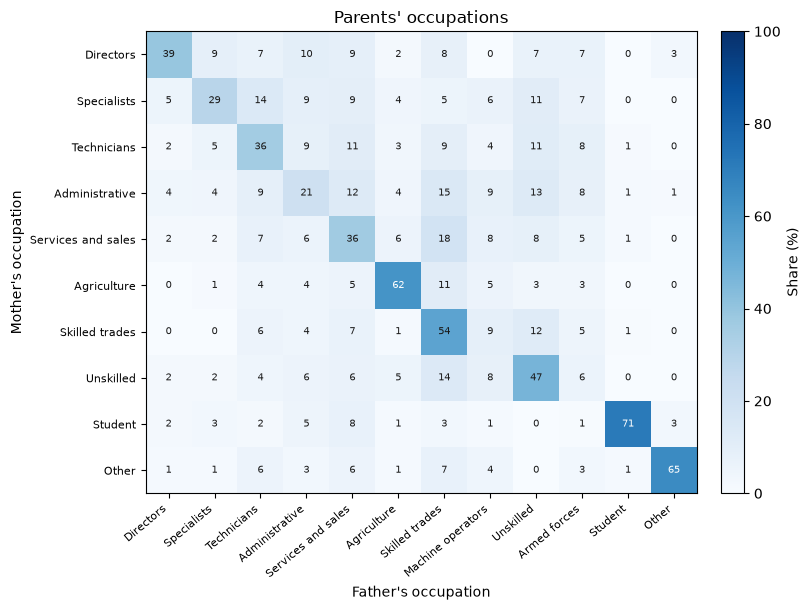

In [78]:
order = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 0, 90]
labels = {
    0: "Student",
    1: "Directors",
    2: "Specialists",
    3: "Technicians",
    4: "Administrative",
    5: "Services and sales",
    6: "Agriculture",
    7: "Skilled trades",
    8: "Machine operators",
    9: "Unskilled",
    10: "Armed forces",
    90: "Other",
}
mother = "Mother's occupation"
father = "Father's occupation"
keep_mother = [code for code in order if (df[mother] == code).sum() >= 50]
keep_father = [code for code in order if (df[father] == code).sum() >= 50]
sub = df[df[mother].isin(keep_mother) & df[father].isin(keep_father)]
shares = (
    pd.crosstab(sub[mother], sub[father], normalize="index")
    .reindex(index=keep_mother, columns=keep_father)
    * 100
)
same = int((sub[mother] == sub[father]).sum())
fig, ax = plt.subplots(figsize=(8.2, 6.2))
image = ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(
    range(len(keep_father)),
    [labels[code] for code in keep_father],
    rotation=40,
    ha="right",
    fontsize=8,
)
ax.set_yticks(range(len(keep_mother)), [labels[code] for code in keep_mother], fontsize=8)
ax.set_xlabel("Father's occupation")
ax.set_ylabel("Mother's occupation")
ax.set_title("Parents' occupations")
for i in range(len(keep_mother)):
    for j in range(len(keep_father)):
        value = shares.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if value >= 55 else "#1A1A1A",
        )
fig.colorbar(image, ax=ax, label="Share (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


Among the 4,268 students included, 1,711 (40.1%) have parents with the same occupation code. The strongest matches are students (71%), agriculture (62%), other (65%), and skilled trades (54%).

**Age at enrolment**

The histogram shows the overall age distribution without separating outcomes.

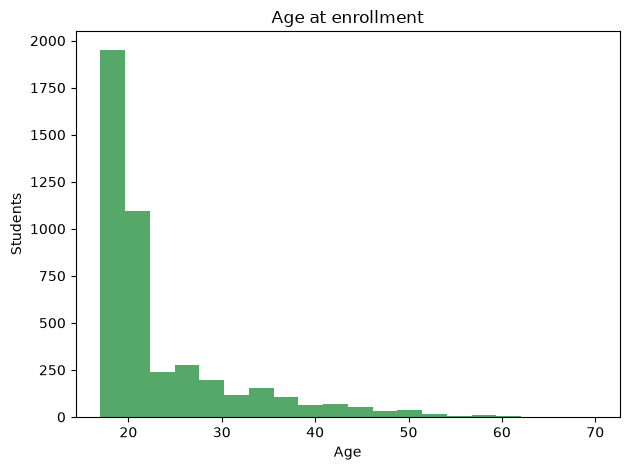

In [79]:
df["Age at enrollment"].plot(kind="hist", bins=20, color="#55A868")
plt.title("Age at enrollment")
plt.xlabel("Age")
plt.ylabel("Students")
plt.tight_layout()
plt.show()


## 5. Feature engineering

We derive new features, prepare categorical and numerical inputs, and define cumulative feature sets for the three prediction stages. Features derived from individual student records can be constructed before splitting; preprocessing parameters are fitted using training data only.

### 5.1 New fields from the curricular units

| New field | Built from |
|---|---|
| `Curricular units missing` | 1 for the 180 course 171 rows whose twelve curricular fields are missing, 0 otherwise |
| `Pass rate 1st sem` | 1st sem approved ÷ 1st sem enrolled |
| `Pass rate 2nd sem` | 2nd sem approved ÷ 2nd sem enrolled |
| `Pass rate overall` | approved units from both semesters ÷ enrolled units from both semesters |

Pass rates account for differences in the number of units taken. Students who pass 5 of 5 and 5 of 10 units have the same approved count but pass rates of 1.0 and 0.5, respectively.

All three pass rates are missing for the 180 affected students and range from 0 to 1 for the remaining students. The missing-data indicator identifies these records using first-semester enrolment, and all original curricular-unit fields are retained.

In [80]:
def add_features(frame):
    """Return a copy of frame with the fields from 5.1 added. Uses each row on its own."""
    out = frame.copy()
    first_enrolled = out["Curricular units 1st sem (enrolled)"]
    second_enrolled = out["Curricular units 2nd sem (enrolled)"]
    first_approved = out["Curricular units 1st sem (approved)"]
    second_approved = out["Curricular units 2nd sem (approved)"]

    out["Curricular units missing"] = first_enrolled.isna().astype(int)
    out["Pass rate 1st sem"] = first_approved / first_enrolled
    out["Pass rate 2nd sem"] = second_approved / second_enrolled
    out["Pass rate overall"] = (first_approved + second_approved) / (first_enrolled + second_enrolled)
    return out


NEW_FIELDS = [
    "Curricular units missing",
    "Pass rate 1st sem",
    "Pass rate 2nd sem",
    "Pass rate overall",
]

data = add_features(df)
assert data["Curricular units missing"].sum() == 180
rates = ["Pass rate 1st sem", "Pass rate 2nd sem", "Pass rate overall"]
assert not np.isinf(data[rates].to_numpy(dtype=float)).any()
assert data[rates].min().min() >= 0 and data[rates].max().max() <= 1

print("rows flagged missing:", int(data["Curricular units missing"].sum()))
print("missing cells per new field:")
print(data[NEW_FIELDS].isna().sum().to_string())
print()
print("median by outcome (180 missing rows left out):")
data.groupby("Target")[NEW_FIELDS[1:]].median().round(2)

rows flagged missing: 180
missing cells per new field:
Curricular units missing      0
Pass rate 1st sem           180
Pass rate 2nd sem           180
Pass rate overall           180

median by outcome (180 missing rows left out):


,Pass rate 1st sem,Pass rate 2nd sem,Pass rate overall
Target,,,
Dropout,0.4,0.17,0.30
Enrolled,0.8,0.71,0.75
Graduate,1.0,1.00,1.00


Median pass rates for graduates are 1.0 in both semesters, compared with 0.80 and 0.71 for enrolled students and 0.40 and 0.17 for dropouts. Students who dropped out had a median overall pass rate of 0.30.

### 5.2 Coding and standardizing

#### Coding

| Field | Coding |
|---|---|
| `Marital status` | one-hot |
| `Application mode` | one-hot |
| `Course` | one-hot |
| `Daytime/evening attendance` | already 0/1 |
| `Previous qualification` | one-hot |
| `Nacionality` | one-hot |
| `Mother's qualification` | one-hot |
| `Father's qualification` | one-hot |
| `Mother's occupation` | one-hot |
| `Father's occupation` | one-hot |
| `Displaced` | already 0/1 |
| `Educational special needs` | already 0/1 |
| `Debtor` | already 0/1 |
| `Tuition fees up to date` | already 0/1 |
| `Gender` | already 0/1 |
| `Scholarship holder` | already 0/1 |
| `International` | already 0/1 |
| `Target` | label, not an input |
| `Curricular units missing` | already 0/1 |

Categorical codes identify categories rather than quantities: course 171 represents Animation and Multimedia Design, while 9500 represents Nursing. One-hot encoding avoids imposing a numerical ordering. Categories occurring fewer than 20 times in the training data are grouped into an infrequent category; unseen categories are assigned there when it exists. Binary fields remain unchanged.

#### Numerical preprocessing

| Configuration | Missing values | Standardization |
|---|---|---|
| Median fill | Training median | Yes |
| Keep missing | Retained | No |

Standardization subtracts the training mean and divides by the training standard deviation. Median imputation allows models that cannot handle missing values to retain all records. Zero imputation is avoided because zero is a meaningful curricular-unit value, not a suitable replacement for missing records. The missing-data indicator remains binary in both configurations.

In [81]:
ONE_HOT = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
AS_RECORDED = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Curricular units missing",
]
MIN_CODE_COUNT = 20

TO_STANDARDIZE = [col for col in data.columns if col not in ONE_HOT + AS_RECORDED + ["Target"]]
assert set(ONE_HOT + AS_RECORDED + TO_STANDARDIZE + ["Target"]) == set(data.columns)
for col in ONE_HOT:
    counts = data[col].value_counts()
    print(f"{col}: {len(counts)} codes, {int((counts >= MIN_CODE_COUNT).sum())} with {MIN_CODE_COUNT}+ students")

Marital status: 6 codes, 4 with 20+ students
Application mode: 18 codes, 12 with 20+ students
Course: 17 codes, 16 with 20+ students
Previous qualification: 17 codes, 8 with 20+ students
Nacionality: 21 codes, 2 with 20+ students
Mother's qualification: 29 codes, 10 with 20+ students
Father's qualification: 34 codes, 10 with 20+ students
Mother's occupation: 32 codes, 12 with 20+ students
Father's occupation: 46 codes, 12 with 20+ students


### 5.3 Feature sets by stage

We construct four feature sets across three prediction stages to assess how early academic outcomes can be predicted.

| Set | Prediction stage | Included features | Count |
|---|---|---|---:|
| A (restricted) | At enrolment | A (full) excluding the three financial fields listed below | 21 |
| A (full) | At enrolment | Demographics, application and admission, family background, socioeconomic factors, and macroeconomic indicators | 24 |
| B | After semester one | A (full) + six first-semester fields, first-semester pass rate, and missing curricular data indicator | 32 |
| C | After semester two | B + six second-semester fields, second-semester pass rate, and overall pass rate | 40 |

Feature counts are before one-hot encoding. Both models are fitted using each feature set and the same train/test split.

The recording time of `Tuition fees up to date`, `Debtor`, and `Scholarship holder` is uncertain. Stage A (restricted) excludes these fields to assess enrolment-time prediction without potentially later information.

In [82]:
FIRST_SEM = [col for col in data.columns if col.startswith("Curricular units 1st sem")]
SECOND_SEM = [col for col in data.columns if col.startswith("Curricular units 2nd sem")]

STAGE_A = [
    col
    for col in data.columns
    if col not in FIRST_SEM + SECOND_SEM + NEW_FIELDS + ["Target"]
]
STAGE_B = STAGE_A + FIRST_SEM + ["Pass rate 1st sem", "Curricular units missing"]
STAGE_C = STAGE_B + SECOND_SEM + ["Pass rate 2nd sem", "Pass rate overall"]
STAGES = {"A": STAGE_A, "B": STAGE_B, "C": STAGE_C}

MONEY_FIELDS = ["Tuition fees up to date", "Debtor", "Scholarship holder"]
FEATURE_SETS = {
    "A (restricted)": [col for col in STAGE_A if col not in MONEY_FIELDS],
    "A (full)": STAGE_A,
    "B": STAGE_B,
    "C": STAGE_C,
}

assert len(STAGE_C) == len(set(STAGE_C)) == data.shape[1] - 1
for name, cols in FEATURE_SETS.items():
    print(f"{name}: {len(cols)} fields")


def make_preprocessor(columns, fill_missing=True):
    """Code the category fields.

    fill_missing=True fills numeric gaps with the training median, then
    standardizes. fill_missing=False keeps the recorded values and the
    missing entries. Fit on the training rows only.
    """
    one_hot = [col for col in columns if col in ONE_HOT]
    as_recorded = [col for col in columns if col in AS_RECORDED]
    to_standardize = [col for col in columns if col in TO_STANDARDIZE]
    if fill_missing:
        numeric_steps = Pipeline(
            [
                ("fill", SimpleImputer(strategy="median")),
                ("standardize", StandardScaler()),
            ]
        )
    else:
        numeric_steps = "passthrough"
    encode = OneHotEncoder(
        min_frequency=MIN_CODE_COUNT,
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
    )
    return ColumnTransformer(
        [
            ("one_hot", encode, one_hot),
            ("standardize", numeric_steps, to_standardize),
            ("as_recorded", "passthrough", as_recorded),
        ]
    )

A (restricted): 21 fields
A (full): 24 fields
B: 32 fields
C: 40 fields


### 5.4 Train/test split

We reserve 20% of students for testing using a stratified split to preserve the outcome distribution. All models use the same split. Preprocessing parameters are fitted using training data only, including within cross-validation folds during hyperparameter tuning.

The following checks verify that median imputation removes missing values and that the keep-missing configuration preserves them.

In [83]:
X = data.drop(columns="Target")
y = data["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"train rows: {len(X_train)}, test rows: {len(X_test)}")
print("train shares:", (y_train.value_counts(normalize=True) * 100).round(1).to_dict())
print("test shares: ", (y_test.value_counts(normalize=True) * 100).round(1).to_dict())
print()

for name, cols in FEATURE_SETS.items():
    for fill_missing, label in ((True, "median fill"), (False, "keep missing")):
        prep = make_preprocessor(cols, fill_missing=fill_missing).fit(X_train[cols])
        train_out = prep.transform(X_train[cols])
        test_out = prep.transform(X_test[cols])
        missing_rows = int(
            np.isnan(train_out).any(axis=1).sum() + np.isnan(test_out).any(axis=1).sum()
        )
        if fill_missing or name in ("A (restricted)", "A (full)"):
            assert missing_rows == 0
        else:
            assert missing_rows == 180
        print(
            f"{name}, {label}: {len(cols)} fields -> {train_out.shape[1]} model inputs, "
            f"rows with a missing value: {missing_rows}"
        )

train rows: 3539, test rows: 885
train shares: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 17.9}
test shares:  {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 18.0}

A (restricted), median fill: 21 fields -> 104 model inputs, rows with a missing value: 0
A (restricted), keep missing: 21 fields -> 104 model inputs, rows with a missing value: 0
A (full), median fill: 24 fields -> 107 model inputs, rows with a missing value: 0
A (full), keep missing: 24 fields -> 107 model inputs, rows with a missing value: 0
B, median fill: 32 fields -> 115 model inputs, rows with a missing value: 0
B, keep missing: 32 fields -> 115 model inputs, rows with a missing value: 180
C, median fill: 40 fields -> 123 model inputs, rows with a missing value: 0
C, keep missing: 40 fields -> 123 model inputs, rows with a missing value: 180


## 6. Modelling

We compare logistic regression and random forest against a majority-class baseline. Hyperparameters are selected using 5-fold stratified cross-validation on the training set, scored by macro F1. All models use the train/test split established in Section 5.4. Sections 6.2 and 6.3 demonstrate each model using Stage C before the comparison across stages.

### 6.1 Baseline

The baseline uses a `DummyClassifier` with the `most_frequent` strategy, predicting the most common training outcome (Graduate) for every student. It provides a reference point for evaluating the other models.

In [84]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predicted = baseline.predict(X_train)
print(f"most common training outcome: {y_train.value_counts().idxmax()}")
print(f"train macro F1: {f1_score(y_train, baseline_predicted, average='macro'):.3f}")

most common training outcome: Graduate
train macro F1: 0.222


### 6.2 Logistic regression

Multinomial logistic regression provides an interpretable linear classification model against which a more complex, nonlinear model can be compared. We use the median-filled, standardized preprocessing configuration from Section 5.2.

#### Cross-validation

We tune `C`, the inverse of regularization strength, over 0.01, 0.1, 1, 10, and 100. Smaller values impose stronger regularization. When cross-validation scores tie to three decimal places, we select the smaller `C`.

In [85]:
from IPython.display import display

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)


def choose_logistic_C(cv_results, best_score):
    # Smallest C among values tied for the best CV score at three decimals.
    best_rounded = round(float(best_score), 3)
    tied = sorted(
        {
            float(c)
            for c, score in zip(cv_results["param_classify__C"], cv_results["mean_test_score"])
            if round(float(score), 3) == best_rounded
        }
    )
    return tied[0], tied


search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(STAGE_C)),
            ("classify", LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)),
        ]
    ),
    param_grid={"classify__C": [0.01, 0.1, 1, 10, 100]},
    scoring="f1_macro",
    cv=cv,
)
search.fit(X_train[STAGE_C], y_train)
chosen_C, tied_Cs = choose_logistic_C(search.cv_results_, search.best_score_)
model = Pipeline(
    [
        ("prep", make_preprocessor(STAGE_C)),
        ("classify", LogisticRegression(C=chosen_C, max_iter=2000, random_state=RANDOM_SEED)),
    ]
).fit(X_train[STAGE_C], y_train)

results = pd.DataFrame(search.cv_results_)[
    ["param_classify__C", "mean_test_score"]
].rename(
    columns={
        "param_classify__C": "C",
        "mean_test_score": "mean 5-fold macro F1",
    }
)
results["C"] = results["C"].astype(float)
results["mean 5-fold macro F1"] = results["mean 5-fold macro F1"].astype(float).round(3)
display(results)
print(f"chosen C: {int(chosen_C) if float(chosen_C).is_integer() else chosen_C}")
if len(tied_Cs) > 1:
    print(f"tied at best CV score: {tied_Cs}; kept the smallest C")

,C,mean 5-fold macro F1
0,0.01,0.658
1,0.10,0.701
2,1.00,0.706
3,10.00,0.710
4,100.00,0.710


chosen C: 10
tied at best CV score: [10.0, 100.0]; kept the smallest C


### 6.3 Random forest

Random forest captures nonlinear relationships and feature interactions. Feature importance scores help identify informative risk indicators at different stages and guide investigation into potential areas for student support. Predictive importance does not establish causality. We use the keep-missing preprocessing configuration from Section 5.2.

#### Cross-validation

| Hyperparameter | Candidate values |
|---|---|
| Number of trees | 100, 300, 500 |
| Maximum tree depth | 10, 20, unrestricted |

In [86]:
forest_search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(STAGE_C, fill_missing=False)),
            ("classify", RandomForestClassifier(random_state=RANDOM_SEED)),
        ]
    ),
    param_grid={
        "classify__n_estimators": [100, 300, 500],
        "classify__max_depth": [None, 10, 20],
    },
    scoring="f1_macro",
    cv=cv,
)
forest_search.fit(X_train[STAGE_C], y_train)
forest_model = forest_search.best_estimator_

results = pd.DataFrame(forest_search.cv_results_)[
    ["param_classify__n_estimators", "param_classify__max_depth", "mean_test_score"]
].rename(
    columns={
        "param_classify__n_estimators": "n_estimators",
        "param_classify__max_depth": "max_depth",
        "mean_test_score": "mean 5-fold macro F1",
    }
)
display(results)
print(f"chosen n_estimators: {forest_search.best_params_['classify__n_estimators']}")
print(f"chosen max_depth: {forest_search.best_params_['classify__max_depth']}")

,n_estimators,max_depth,mean 5-fold macro F1
0,100,None,0.687443
1,300,None,0.690950
2,500,None,0.690186
3,100,10,0.683739
4,300,10,0.679926
5,500,10,0.680045
6,100,20,0.694962
7,300,20,0.693150
8,500,20,0.698489


chosen n_estimators: 500
chosen max_depth: 20


### 6.4 Modelling across stages

Both models are tuned separately for each of the four feature sets defined in Section 5.3 to investigate how predictive performance changes as additional information becomes available.

#### Cross-validation

The table reports the selected hyperparameters and cross-validation scores for each model and feature set.

In [87]:
from IPython.display import display

MODELS = {
    "Logistic regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
        {"classify__C": [0.01, 0.1, 1, 10, 100]},
        True,
    ),
    "Random forest": (
        RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1),
        {"classify__n_estimators": [100, 300, 500], "classify__max_depth": [None, 10, 20]},
        False,
    ),
}

stage_choices = {}
cv_rows = []
for model_name, (estimator, grid, fill_missing) in MODELS.items():
    for set_name, cols in FEATURE_SETS.items():
        search = GridSearchCV(
            Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=fill_missing)),
                    ("classify", estimator),
                ]
            ),
            param_grid=grid,
            scoring="f1_macro",
            cv=cv,
        )
        search.fit(X_train[cols], y_train)
        if model_name == "Logistic regression":
            chosen_C, _ = choose_logistic_C(search.cv_results_, search.best_score_)
            params = {"C": chosen_C}
            settings = f"C={int(chosen_C) if float(chosen_C).is_integer() else chosen_C}"
        else:
            params = {
                key.removeprefix("classify__"): value
                for key, value in search.best_params_.items()
            }
            settings = ", ".join(f"{key}={value}" for key, value in params.items())
        stage_choices[(model_name, set_name)] = {
            "cols": cols,
            "fill_missing": fill_missing,
            "params": params,
            "settings": settings,
            "cv_score": search.best_score_,
        }
        cv_rows.append(
            {
                "model": model_name,
                "features": set_name,
                "fields": len(cols),
                "settings": settings,
                "CV macro F1": search.best_score_,
            }
        )

stage_cv = pd.DataFrame(cv_rows)
display(stage_cv.round(3))


,model,features,fields,settings,CV macro F1
0,Logistic regression,A (restricted),21,C=10,0.498
1,Logistic regression,A (full),24,C=100,0.555
2,Logistic regression,B,32,C=10,0.671
3,Logistic regression,C,40,C=10,0.710
4,Random forest,A (restricted),21,"max_depth=None, n_estimators=100",0.480
5,Random forest,A (full),24,"max_depth=None, n_estimators=500",0.530
6,Random forest,B,32,"max_depth=None, n_estimators=300",0.663
7,Random forest,C,40,"max_depth=20, n_estimators=500",0.698


#### Fitting

Each model is fitted on the full training set using its selected hyperparameters. The fitted models are retained for evaluation in Section 7.

In [88]:
def test_scores(y_true, y_pred):
    precision, recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=["Dropout"], zero_division=0
    )
    return {
        "test macro F1": f1_score(y_true, y_pred, average="macro"),
        "dropout recall": recall[0],
        "dropout precision": precision[0],
        "accuracy": accuracy_score(y_true, y_pred),
    }


rows = [
    {
        "model": "Baseline (always Graduate)",
        "features": "any",
        "fields": "-",
        "settings": "-",
        "CV macro F1": np.nan,
        **test_scores(y_test, baseline.predict(X_test)),
    }
]
stage_models = {}
for model_name in MODELS:
    for set_name, cols in FEATURE_SETS.items():
        choice = stage_choices[(model_name, set_name)]
        params = choice["params"]
        if model_name == "Logistic regression":
            fitted = Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=True)),
                    (
                        "classify",
                        LogisticRegression(
                            C=params["C"], max_iter=2000, random_state=RANDOM_SEED
                        ),
                    ),
                ]
            ).fit(X_train[cols], y_train)
        else:
            fitted = Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=False)),
                    (
                        "classify",
                        RandomForestClassifier(
                            n_estimators=params["n_estimators"],
                            max_depth=params["max_depth"],
                            random_state=RANDOM_SEED,
                            n_jobs=-1,
                        ),
                    ),
                ]
            ).fit(X_train[cols], y_train)
        stage_models[(model_name, set_name)] = fitted
        rows.append(
            {
                "model": model_name,
                "features": set_name,
                "fields": len(cols),
                "settings": choice["settings"],
                "CV macro F1": choice["cv_score"],
                **test_scores(y_test, fitted.predict(X_test[cols])),
            }
        )

stage_results = pd.DataFrame(rows)
print(f"fitted models: {len(stage_models)}")
print(f"feature sets: {list(FEATURE_SETS)}")


fitted models: 8
feature sets: ['A (restricted)', 'A (full)', 'B', 'C']


## 7. Evaluation

We compare the models across feature sets on the held-out test set, examine class-level performance and errors, and assess discrimination, training set size, and subgroup performance. Feature importance helps identify informative risk indicators.

### 7.1 Comparison across stages

We evaluate the fitted models from Section 6.4 and the majority-class baseline on the held-out test set using macro F1 and dropout recall, the two principal evaluation metrics established in Section 1.

In [89]:
evaluation_columns = {
    "model": "Model",
    "features": "Feature set",
    "test macro F1": "Macro F1",
    "dropout recall": "Dropout recall",
}

display(
    stage_results[list(evaluation_columns)]
    .rename(columns=evaluation_columns)
    .replace({"Feature set": {"any": "—"}})
    .round(3)
)

,Model,Feature set,Macro F1,Dropout recall
0,Baseline (always Graduate),—,0.222,0.000
1,Logistic regression,A (restricted),0.468,0.496
2,Logistic regression,A (full),0.521,0.588
3,Logistic regression,B,0.672,0.739
4,Logistic regression,C,0.700,0.768
5,Random forest,A (restricted),0.470,0.525
6,Random forest,A (full),0.515,0.606
7,Random forest,B,0.641,0.746
8,Random forest,C,0.716,0.782


The plots compare macro F1 and dropout recall across the four feature sets. The dashed lines show the majority-class baseline.

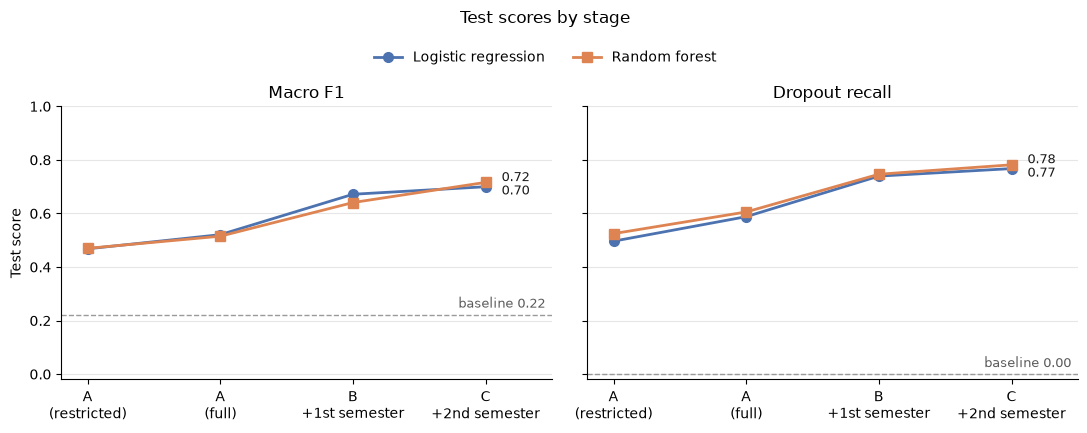

In [90]:
stage_order = ["A (restricted)", "A (full)", "B", "C"]
stage_ticks = [
    "A\n(restricted)",
    "A\n(full)",
    "B\n+1st semester",
    "C\n+2nd semester",
]
model_styles = {
    "Logistic regression": ("#4C72B0", "o"),
    "Random forest": ("#DD8452", "s"),
}
measures = [("test macro F1", "Macro F1"), ("dropout recall", "Dropout recall")]
baseline_row = stage_results.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (column, title) in zip(axes, measures):
    ax.axhline(baseline_row[column], color="#9A9A9A", linewidth=1, linestyle="--")
    ax.text(
        3.45,
        baseline_row[column] + 0.015,
        f"baseline {baseline_row[column]:.2f}",
        color="#5A5A5A",
        fontsize=9,
        va="bottom",
        ha="right",
    )
    end_labels = []
    for model_name, (color, marker) in model_styles.items():
        values = (
            stage_results[stage_results["model"] == model_name]
            .set_index("features")
            .loc[stage_order, column]
        )
        ax.plot(
            range(len(stage_order)),
            values.to_numpy(),
            color=color,
            marker=marker,
            linewidth=2,
            markersize=7,
            label=model_name,
        )
        end_labels.append([values.iloc[-1], f"{values.iloc[-1]:.2f}"])
    end_labels.sort()
    if end_labels[1][0] - end_labels[0][0] < 0.05:
        middle = (end_labels[0][0] + end_labels[1][0]) / 2
        end_labels[0][0], end_labels[1][0] = middle - 0.025, middle + 0.025
    for position, text in end_labels:
        ax.text(3.12, position, text, color="#1A1A1A", fontsize=9, va="center")
    ax.set_title(title)
    ax.set_xlim(-0.2, 3.5)
    ax.set_xticks(range(len(stage_order)), stage_ticks)
    ax.set_ylim(-0.02, 1.0)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Test score")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Test scores by stage", y=1.07)
fig.tight_layout()
plt.show()


Both models outperform the majority-class baseline at every stage.

**Enrolment.** Including the financial fields improves both macro F1 and dropout recall for both models. However, Stage A (restricted) provides a more conservative estimate of enrolment-time predictive performance because the recording time of these fields is uncertain.

**Semester results.** Adding first-semester results produces the largest improvement in both metrics, with dropout recall reaching approximately 74% for both models. Second-semester results provide smaller additional gains, suggesting that first-semester results may offer a useful balance between predictive performance and opportunities for early intervention.

**Model comparison.** Logistic regression achieves higher cross-validation macro F1 at every stage, while random forest consistently achieves higher test dropout recall. Neither model consistently outperforms the other across all stages and metrics.

#### Uncertainty in performance differences

We use 2,000 paired bootstrap resamples of the same test students to estimate 95% intervals for score differences. Intervals describe test-sample uncertainty conditional on the fitted models; they do not include variation from training or tuning.

In [ ]:
all_predictions = {
    key: fitted.predict(X_test[FEATURE_SETS[key[1]]])
    for key, fitted in stage_models.items()
}

N_DRAWS = 2000
actual_values = y_test.to_numpy()
draws = np.random.default_rng(RANDOM_SEED).integers(
    0, len(actual_values), (N_DRAWS, len(actual_values))
)


def macro_f1(actual, guesses):
    return f1_score(actual, guesses, average="macro")


def dropout_recall(actual, guesses):
    return (guesses[actual == "Dropout"] == "Dropout").mean()


LR, RF = "Logistic regression", "Random forest"
COMPARISONS = [
    ("random forest minus logistic regression, B", (RF, "B"), (LR, "B")),
    ("random forest minus logistic regression, C", (RF, "C"), (LR, "C")),
    ("logistic regression: A (full) minus A (restricted)", (LR, "A (full)"), (LR, "A (restricted)")),
    ("logistic regression: B minus A (full)", (LR, "B"), (LR, "A (full)")),
    ("logistic regression: C minus B", (LR, "C"), (LR, "B")),
    ("random forest: A (full) minus A (restricted)", (RF, "A (full)"), (RF, "A (restricted)")),
    ("random forest: B minus A (full)", (RF, "B"), (RF, "A (full)")),
    ("random forest: C minus B", (RF, "C"), (RF, "B")),
]
drawn_scores = {}
for key, guesses in all_predictions.items():
    if key[0] == BASELINE_NAME:
        continue
    for label, scorer in (("macro F1", macro_f1), ("dropout recall", dropout_recall)):
        drawn_scores[(key, label)] = np.array(
            [scorer(actual_values[draw], guesses[draw]) for draw in draws]
        )

gap_rows = []
for name, first, second in COMPARISONS:
    row = {"comparison": name}
    for label, scorer in (("macro F1", macro_f1), ("dropout recall", dropout_recall)):
        gap = scorer(actual_values, all_predictions[first]) - scorer(
            actual_values, all_predictions[second]
        )
        low_end, high_end = np.percentile(
            drawn_scores[(first, label)] - drawn_scores[(second, label)], [2.5, 97.5]
        )
        row[f"{label} gap"] = f"{gap:+.3f}"
        row[f"{label} 95% interval"] = f"{low_end:+.3f} to {high_end:+.3f}"
    gap_rows.append(row)
gap_results = pd.DataFrame(gap_rows).set_index("comparison")
display(gap_results)

,macro F1 gap,macro F1 95% interval,dropout recall gap,dropout recall 95% interval
"random forest minus logistic regression, B",-0.031,-0.066 to +0.005,+0.007,-0.034 to +0.048
"random forest minus logistic regression, C",+0.016,-0.018 to +0.051,+0.014,-0.022 to +0.050
logistic regression: A (full) minus A (restricted),+0.053,+0.027 to +0.079,+0.092,+0.040 to +0.144
logistic regression: B minus A (full),+0.151,+0.117 to +0.186,+0.151,+0.095 to +0.208
logistic regression: C minus B,+0.028,+0.003 to +0.053,+0.028,-0.007 to +0.063
random forest: A (full) minus A (restricted),+0.045,+0.012 to +0.078,+0.081,+0.022 to +0.137
random forest: B minus A (full),+0.126,+0.086 to +0.164,+0.141,+0.082 to +0.198
random forest: C minus B,+0.075,+0.042 to +0.109,+0.035,+0.000 to +0.072


The saved comparisons indicate that adding first-semester results improves both metrics for both models. The second semester improves macro F1, but the intervals for additional dropout recall include zero. Neither model has a clearly established advantage over the other at Stage B or C. These are exploratory comparisons, not evidence of equivalence.

### 7.2 Class-level performance

We compare precision, recall, and F1 for each outcome across both models and all four feature sets. The same test students are used throughout (284 Dropout, 159 Enrolled, and 442 Graduate). The table groups metrics by outcome, while the grouped bar charts compare class-level F1 scores on a common scale.

Dropout                Enrolled         \
                                   Precision Recall     F1 Precision Recall   
Feature set    Model                                                          
A (restricted) Logistic regression     0.560  0.496  0.526     0.323  0.126   
               Random forest           0.569  0.525  0.546     0.340  0.113   
A (full)       Logistic regression     0.668  0.588  0.625     0.305  0.157   
               Random forest           0.630  0.606  0.618     0.432  0.119   
B              Logistic regression     0.781  0.739  0.759     0.496  0.365   
               Random forest           0.754  0.746  0.750     0.514  0.239   
C              Logistic regression     0.790  0.768  0.779     0.548  0.396   
               Random forest           0.819  0.782  0.800     0.629  0.384   

                                           Graduate                
                                       F1 Precision Recall     F1  
Feature set    Model                                               
A (restricted) Logistic regression  0.181     0.618  0.799  0.697  
               Random forest        0.170     0.616  0.794  0.694  
A (full)       Logistic regression  0.207     0.656  0.821  0.730  
               Random forest        0.187     0.658  0.846  0.741  
B              Logistic regression  0.420     0.788  0.889  0.835  
               Random forest        0.326     0.775  0.930  0.846  
C              Logistic regression  0.460     0.816  0.912  0.861  
               Random forest        0.477     0.809  0.946  0.872

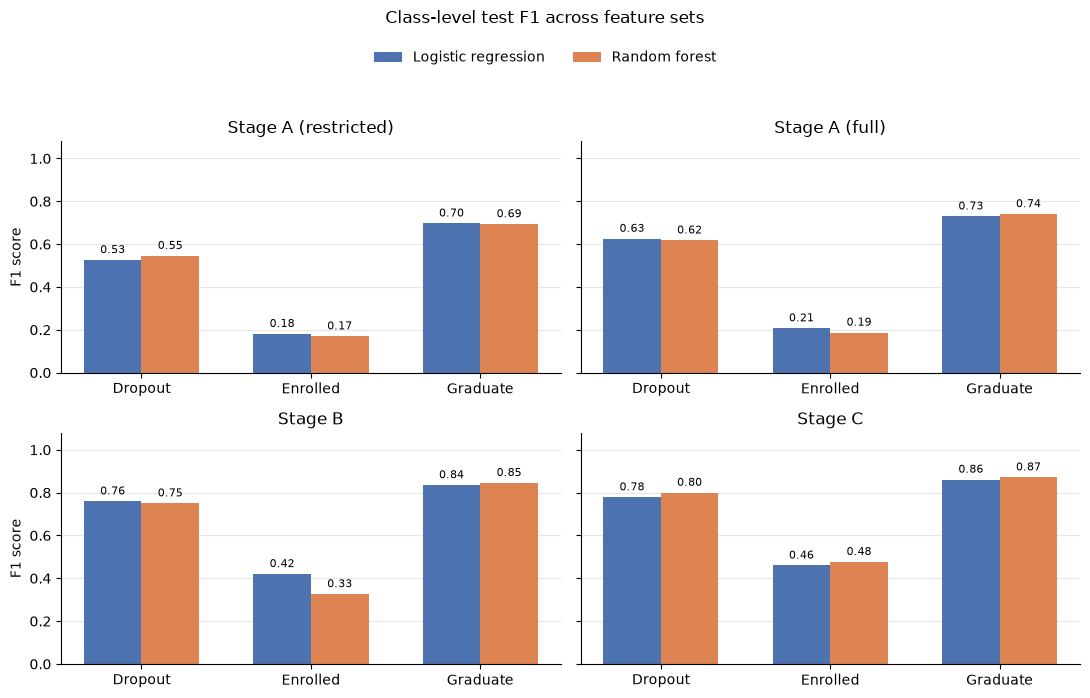

In [91]:
CLASS_OUTCOMES = ["Dropout", "Enrolled", "Graduate"]
class_rows = []
class_predictions = {}

for set_name in stage_order:
    for model_name in MODELS:
        key = (model_name, set_name)
        guesses = stage_models[key].predict(X_test[FEATURE_SETS[set_name]])
        class_predictions[key] = guesses
        precision, recall, f1, support = precision_recall_fscore_support(
            y_test, guesses, labels=CLASS_OUTCOMES, zero_division=0
        )
        for outcome, p, r, f, count in zip(
            CLASS_OUTCOMES, precision, recall, f1, support
        ):
            class_rows.append({
                "Feature set": set_name,
                "Model": model_name,
                "Outcome": outcome,
                "Precision": p,
                "Recall": r,
                "F1": f,
                "Support": int(count),
            })

class_results = pd.DataFrame(class_rows)
# Retain the Stage C logistic regression predictions for Section 7.3.
predicted = class_predictions[("Logistic regression", "C")]

class_table = class_results.pivot(
    index=["Feature set", "Model"],
    columns="Outcome",
    values=["Precision", "Recall", "F1"],
).swaplevel(0, 1, axis=1)
class_table = class_table.reindex(
    index=pd.MultiIndex.from_product(
        [stage_order, list(MODELS)], names=["Feature set", "Model"]
    ),
    columns=pd.MultiIndex.from_product(
        [CLASS_OUTCOMES, ["Precision", "Recall", "F1"]]
    ),
)
display(class_table.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
x = np.arange(len(CLASS_OUTCOMES))
width = 0.34
for ax, set_name in zip(axes.flat, stage_order):
    for i, model_name in enumerate(MODELS):
        scores = (class_results.loc[
            (class_results["Feature set"] == set_name)
            & (class_results["Model"] == model_name)
        ].set_index("Outcome").loc[CLASS_OUTCOMES, "F1"])
        color = model_styles[model_name][0]
        bars = ax.bar(x + (i - 0.5) * width, scores, width,
                      color=color, label=model_name)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_title(f"Stage {set_name}")
    ax.set_xticks(x, CLASS_OUTCOMES)
    ax.set_ylim(0, 1.08)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("F1 score")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Class-level test F1 across feature sets", y=0.99)
fig.legend(handles, labels, loc="upper center", ncol=2,
           frameon=False, bbox_to_anchor=(0.5, 0.95))
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

The existing Stage C results show that both models perform less well on Enrolled (F1 approximately 0.46–0.48) than on Dropout (0.78–0.80) or Graduate (0.86–0.87). Since macro F1 weights all outcomes equally, weaker performance on Enrolled is a limitation. The confusion matrices in Section 7.3 examine these errors more closely.

The comparison across all four feature sets will be interpreted once the expanded analysis has been run.

### 7.3 Confusion matrices

We compare both models across all four feature sets. Rows represent actual outcomes and columns represent predicted outcomes. Each cell shows the percentage of its actual class and the raw count in parentheses. Green indicates correct predictions and red indicates errors; colour intensity uses a common 0–100% scale.

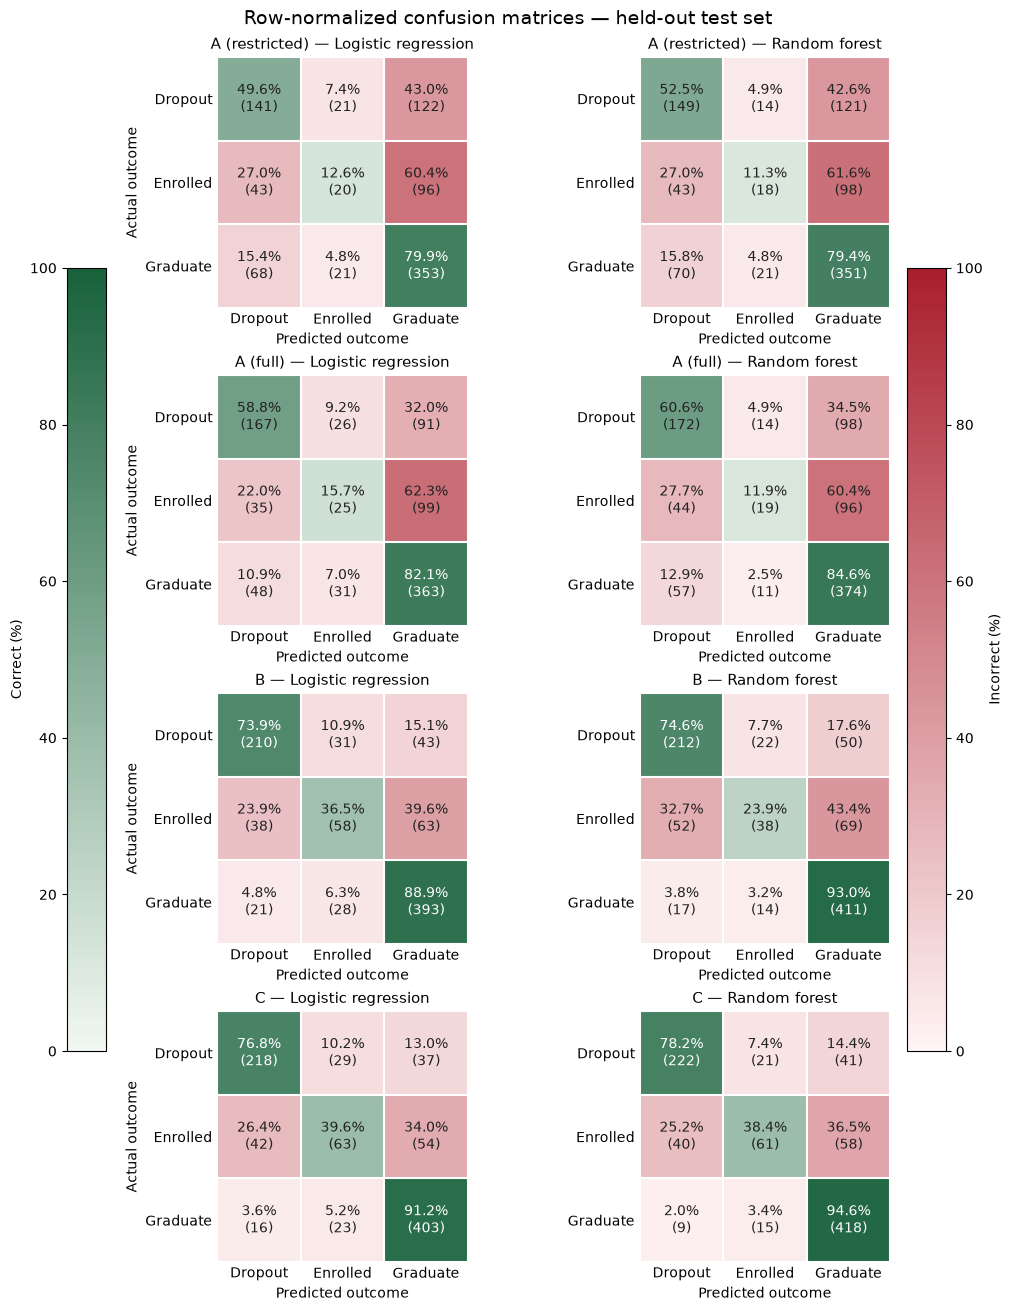

In [92]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

CLASSES = CLASS_OUTCOMES
BASELINE_NAME = "Baseline (always Graduate)"
# Preserve predictions used by subsequent error analyses.
stage_c_predictions = {
    BASELINE_NAME: baseline.predict(X_test),
    **{name: class_predictions[(name, "C")] for name in MODELS},
}

correct_cmap = LinearSegmentedColormap.from_list("correct", ["#F2F8F2", "#17613B"])
error_cmap = LinearSegmentedColormap.from_list("incorrect", ["#FFF4F4", "#A91E2C"])
norm = Normalize(vmin=0, vmax=100)
fig, axes = plt.subplots(4, 2, figsize=(10, 13), layout="constrained")
confusion_results = {}
for row, set_name in enumerate(stage_order):
    for col, model_name in enumerate(MODELS):
        ax = axes[row, col]
        matrix = confusion_matrix(y_test, class_predictions[(model_name, set_name)], labels=CLASSES)
        shares = matrix / matrix.sum(axis=1, keepdims=True) * 100
        confusion_results[(model_name, set_name)] = matrix
        rgba = np.empty((*matrix.shape, 4))
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                cmap = correct_cmap if i == j else error_cmap
                rgba[i, j] = cmap(norm(shares[i, j]))
                r, g, blue, _ = rgba[i, j]
                luminance = 0.2126*r + 0.7152*g + 0.0722*blue
                ax.text(j, i, f"{shares[i, j]:.1f}%\n({matrix[i, j]})",
                        ha="center", va="center", fontsize=10,
                        color="white" if luminance < 0.48 else "#222222")
        ax.imshow(rgba)
        ax.set_xticks(range(len(CLASSES)), CLASSES)
        ax.set_yticks(range(len(CLASSES)), CLASSES)
        ax.set_title(f"{set_name} — {model_name}", fontsize=11)
        ax.set_xlabel("Predicted outcome")
        if col == 0:
            ax.set_ylabel("Actual outcome")
        ax.tick_params(length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks(np.arange(-.5, len(CLASSES), 1), minor=True)
        ax.set_yticks(np.arange(-.5, len(CLASSES), 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1.5)
        ax.tick_params(which="minor", bottom=False, left=False)
fig.colorbar(ScalarMappable(norm=norm, cmap=correct_cmap), ax=axes[:, 0],
             label="Correct (%)", shrink=0.65, location="left")
fig.colorbar(ScalarMappable(norm=norm, cmap=error_cmap), ax=axes[:, 1],
             label="Incorrect (%)", shrink=0.65)
fig.suptitle("Row-normalized confusion matrices — held-out test set", fontsize=14)
plt.show()

The diagonal gives recall for each outcome; the off-diagonal cells identify which outcomes are confused. In particular, predicting Graduate for an eventual dropout may cause an opportunity for early support to be missed. The matrices show how these errors change as academic results become available.

### 7.4 ROC curves

We evaluate each outcome against the other two using one-vs-rest ROC curves. Each curve shows the true positive rate and false positive rate as the probability threshold varies. AUC measures the probability that a randomly selected student with the outcome receives a higher score than a student without it (with ties counted as half). The majority-class baseline has an AUC of 0.50.

We compare Stages B and C to examine discrimination after each semester.

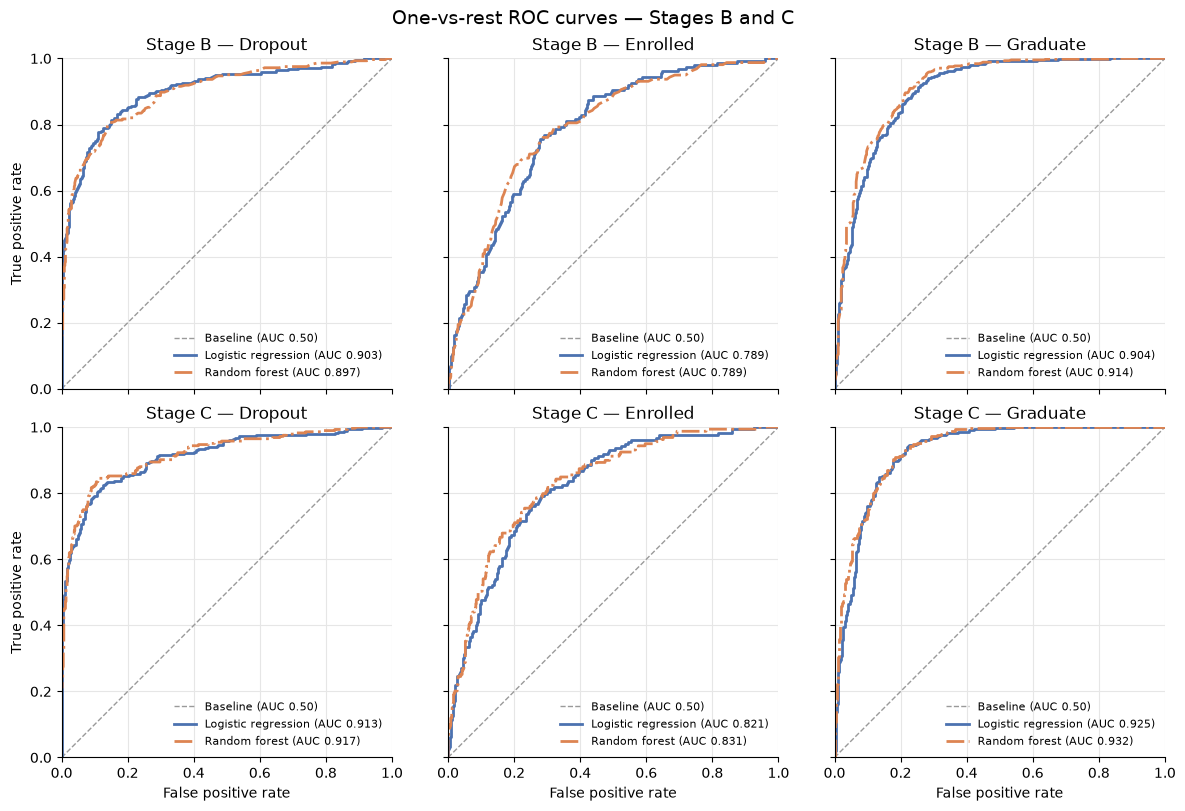

In [93]:
def outcome_chances(model_name, set_name):
    """Predicted chance of each outcome for the test students."""
    if model_name == BASELINE_NAME:
        fitted, columns = baseline, list(X_test.columns)
    else:
        fitted, columns = stage_models[(model_name, set_name)], FEATURE_SETS[set_name]
    return pd.DataFrame(
        fitted.predict_proba(X_test[columns]), columns=fitted.classes_, index=X_test.index
    )


auc_rows = []
for model_name, set_name in [(BASELINE_NAME, "any"), *stage_models]:
    chances = outcome_chances(model_name, set_name)
    row = {"model": model_name, "features": set_name}
    for outcome in CLASSES:
        row[f"AUC {outcome}"] = roc_auc_score((y_test == outcome).to_numpy(), chances[outcome])
    row["mean AUC"] = np.mean([row[f"AUC {outcome}"] for outcome in CLASSES])
    auc_rows.append(row)
auc_results = pd.DataFrame(auc_rows)

curve_styles = {
    "Logistic regression": ("#4C72B0", "-"),
    "Random forest": ("#DD8452", "-."),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True,
                         layout="constrained")
for row, set_name in enumerate(["B", "C"]):
    probabilities = {name: outcome_chances(name, set_name) for name in MODELS}
    for col, outcome in enumerate(CLASSES):
        ax = axes[row, col]
        is_outcome = (y_test == outcome).to_numpy()
        ax.plot([0, 1], [0, 1], color="#9A9A9A", linestyle="--", linewidth=1,
                label="Baseline (AUC 0.50)")
        for name, (color, style) in curve_styles.items():
            chance = probabilities[name][outcome]
            fpr, tpr, _ = roc_curve(is_outcome, chance)
            auc = roc_auc_score(is_outcome, chance)
            ax.plot(fpr, tpr, color=color, linestyle=style, linewidth=2,
                    label=f"{name} (AUC {auc:.3f})")
        ax.set_title(f"Stage {set_name} — {outcome}")
        ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal")
        ax.grid(color="#E6E6E6", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="lower right", frameon=False, fontsize=8)
        if col == 0:
            ax.set_ylabel("True positive rate")
        if row == 1:
            ax.set_xlabel("False positive rate")
fig.suptitle("One-vs-rest ROC curves — Stages B and C", fontsize=14)
plt.show()


Both models distinguish Dropout and Graduate well after the first semester, with further improvements after the second. Enrolled remains the least distinguishable outcome, although its Stage C AUC exceeds 0.80 for both models. This contrasts with its lower recall in Section 7.2: the models can rank students by their likelihood of remaining enrolled more effectively than their final class assignments suggest. Alternative decision thresholds could be explored in future work, with their trade-offs evaluated on validation data.

### 7.5 Training set size

We use learning curves to examine whether additional student records could improve predictive performance at Stages B and C. We retain the hyperparameters selected in Section 6.4 and use five stratified cross-validation folds. At each of seven training sizes (10–100% of the available fold-training records), two random stratified subsets are drawn without replacement within each fold; the largest size uses one draw per fold. The same subsets are used for all four model-stage combinations.

The curves show mean macro F1 on the sampled training records and the cross-validation test folds. Shading indicates one standard deviation across the fits, not a confidence interval. Preprocessing is refitted for each subset, and the independent test set from Section 5.4 is not used.

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


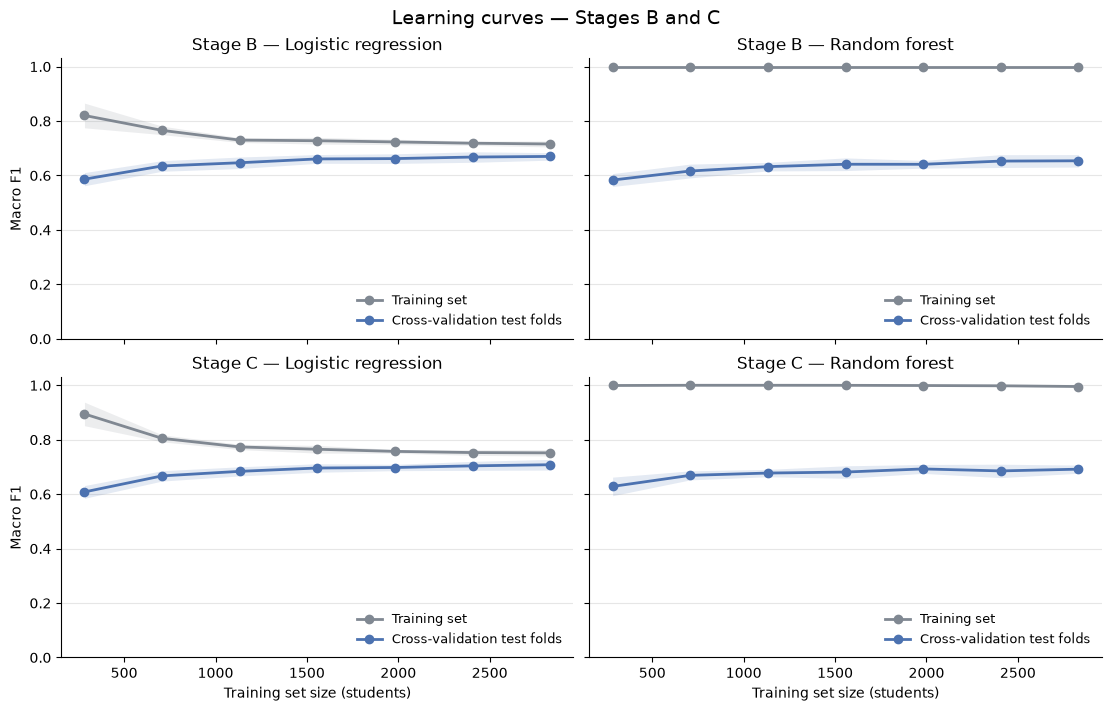

In [94]:
from sklearn.base import clone
from joblib import Parallel, delayed

folds = list(cv.split(X_train, y_train))
max_size = min(len(train_idx) for train_idx, _ in folds)
sizes = (np.linspace(0.1, 1.0, 7) * max_size).astype(int)
rng = np.random.default_rng(RANDOM_SEED)
subsets = []
for train_idx, test_idx in folds:
    for size in sizes:
        for _ in range(1 if size == max_size else 2):
            if size == max_size:
                sample = rng.choice(train_idx, size=int(size), replace=False)
            else:
                sample, _ = train_test_split(
                    train_idx, train_size=int(size), stratify=y_train.iloc[train_idx],
                    random_state=int(rng.integers(0, 2**31 - 1)),
                )
            subsets.append((size, sample, test_idx))


def learning_scores(name, stage, size, sample, test_idx):
    cols = FEATURE_SETS[stage]
    estimator = clone(stage_models[(name, stage)])
    if name == "Random forest":
        estimator.set_params(classify__n_jobs=1)
    X_sample, y_sample = X_train.iloc[sample][cols], y_train.iloc[sample]
    X_fold, y_fold = X_train.iloc[test_idx][cols], y_train.iloc[test_idx]
    estimator.fit(X_sample, y_sample)
    return {"model": name, "stage": stage, "students": size,
            "training": f1_score(y_sample, estimator.predict(X_sample), average="macro"),
            "fold_test": f1_score(y_fold, estimator.predict(X_fold), average="macro")}


learning_runs = pd.DataFrame(Parallel(n_jobs=4)(
    delayed(learning_scores)(name, stage, size, sample, test_idx)
    for stage in ("B", "C") for name in MODELS
    for size, sample, test_idx in subsets
))
size_results = {}
for (name, stage), group in learning_runs.groupby(["model", "stage"], sort=False):
    size_results[(name, stage)] = group.groupby("students").agg(
        training_mean=("training", "mean"), training_std=("training", "std"),
        fold_test_mean=("fold_test", "mean"), fold_test_std=("fold_test", "std"),
    ).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True,
                         layout="constrained")
for row, stage in enumerate(("B", "C")):
    for col, name in enumerate(MODELS):
        ax = axes[row, col]
        table = size_results[(name, stage)]
        x = table["students"].to_numpy()
        for key, color, label in (
            ("training", "#808892", "Training set"),
            ("fold_test", "#4C72B0", "Cross-validation test folds"),
        ):
            mean = table[f"{key}_mean"].to_numpy()
            std = table[f"{key}_std"].to_numpy()
            ax.plot(x, mean, color=color, marker="o", linewidth=2, label=label)
            ax.fill_between(x, np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1),
                            color=color, alpha=0.15, linewidth=0)
        ax.set_title(f"Stage {stage} — {name}")
        ax.set_ylim(0, 1.03)
        ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        if col == 0:
            ax.set_ylabel("Macro F1")
        if row == 1:
            ax.set_xlabel("Training set size (students)")
        ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Learning curves — Stages B and C", fontsize=14)
plt.show()

The gap between training and cross-validation test-fold performance helps assess overfitting. An improving test-fold curve suggests that more distinct student records may help, whereas a flattening curve indicates diminishing gains over the observed sizes. These curves cannot establish performance beyond the available dataset or identify the cause of remaining error.

### 7.6 Subgroup performance

We compare both models at Stage B to investigate potential differences in early dropout detection across student groups. Dropout recall is the proportion of actual dropouts flagged; the false positive rate is the proportion of non-dropouts incorrectly flagged. The labels beside each panel show the number of eligible students for that metric; the group labels show total test students.

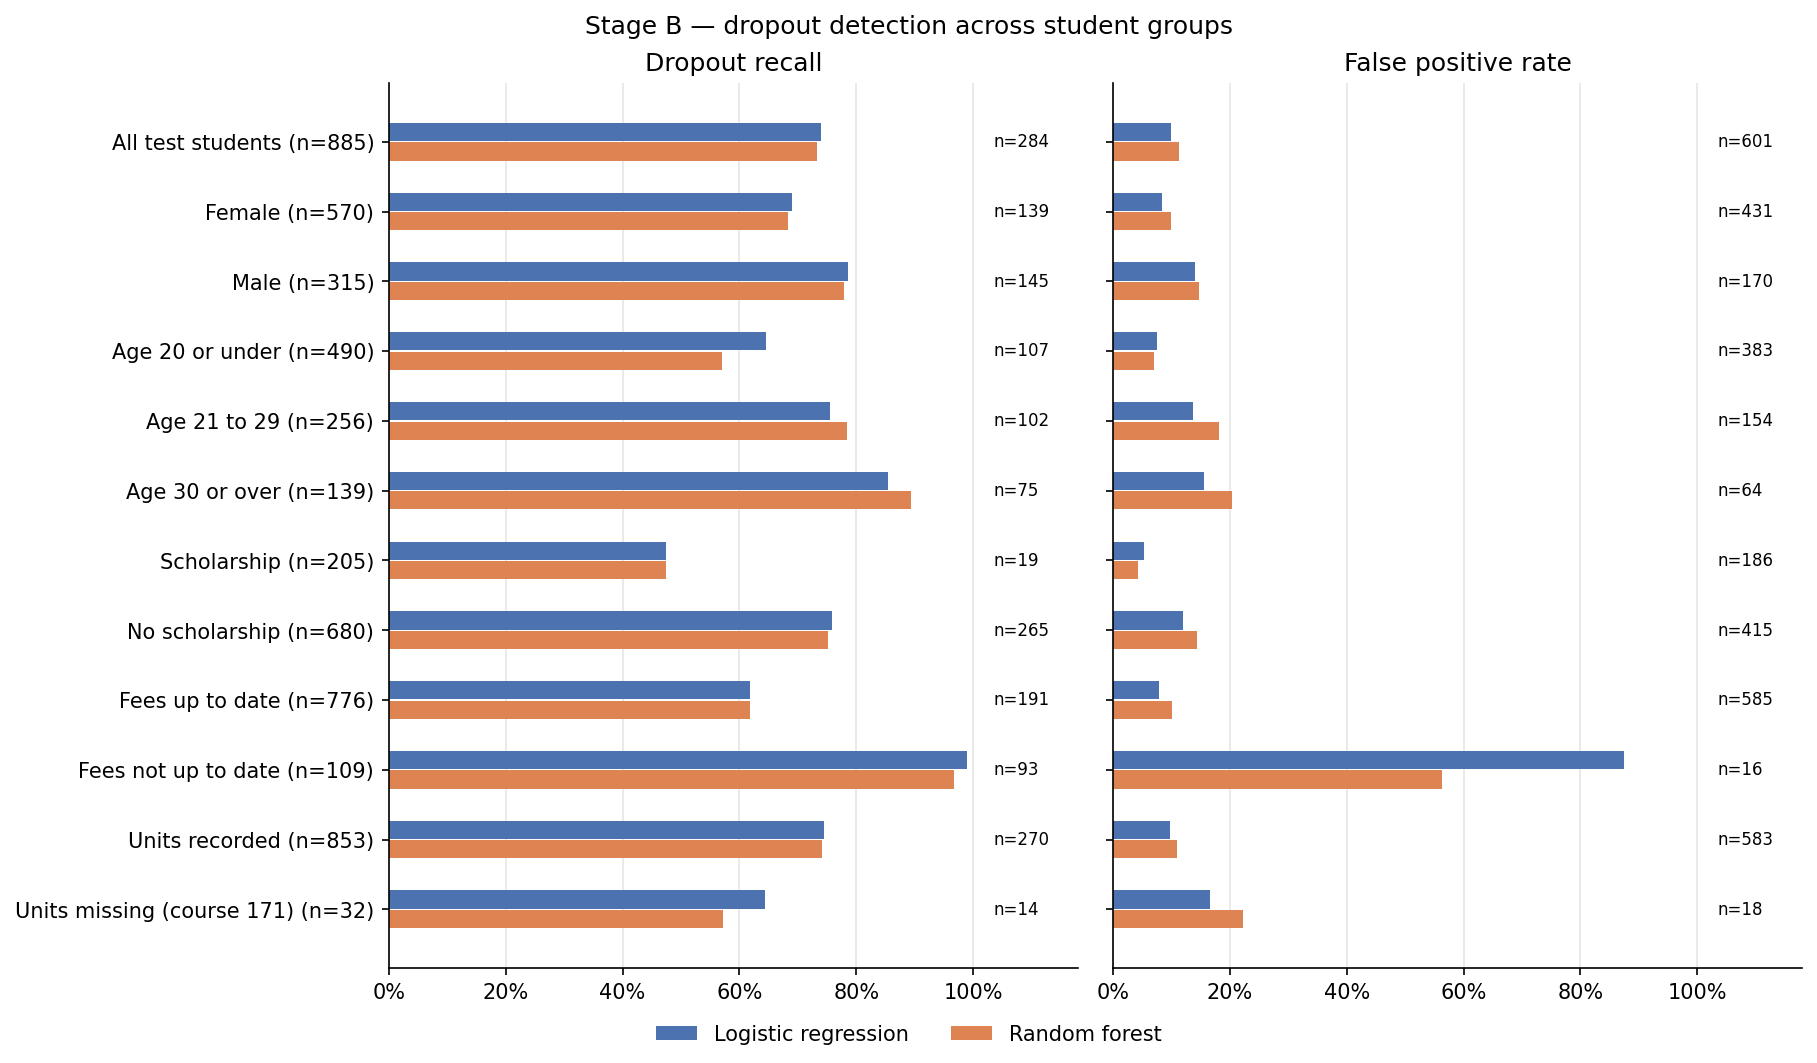

In [ ]:
GROUPS = {
    "All test students": pd.Series(True, index=X_test.index),
    "Female": X_test["Gender"] == 0,
    "Male": X_test["Gender"] == 1,
    "Age 20 or under": X_test["Age at enrollment"] <= 20,
    "Age 21 to 29": X_test["Age at enrollment"].between(21, 29),
    "Age 30 or over": X_test["Age at enrollment"] >= 30,
    "Scholarship": X_test["Scholarship holder"] == 1,
    "No scholarship": X_test["Scholarship holder"] == 0,
    "Fees up to date": X_test["Tuition fees up to date"] == 1,
    "Fees not up to date": X_test["Tuition fees up to date"] == 0,
    "Units recorded": X_test["Curricular units missing"] == 0,
    "Units missing (course 171)": X_test["Curricular units missing"] == 1,
}

group_rows = []
for model_name in MODELS:
    guesses = pd.Series(class_predictions[(model_name, "B")], index=X_test.index)
    for group, members in GROUPS.items():
        actual = y_test[members]
        dropped = actual == "Dropout"
        flagged = guesses[members] == "Dropout"
        for metric, eligible in [("Dropout recall", dropped), ("False positive rate", ~dropped)]:
            total = int(eligible.sum())
            successes = int((eligible & flagged).sum())
            group_rows.append({
                "Model": model_name, "Group": group, "Metric": metric,
                "Students": len(actual), "Eligible": total, "Flagged": successes,
                "Rate": successes / total if total else np.nan,
            })

group_results = pd.DataFrame(group_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True, layout="constrained")
positions = np.arange(len(GROUPS))
for ax, metric in zip(axes, ["Dropout recall", "False positive rate"]):
    for i, model_name in enumerate(MODELS):
        scores = (group_results[(group_results["Metric"] == metric)
                                 & (group_results["Model"] == model_name)]
                  .set_index("Group").loc[list(GROUPS)])
        y_pos = positions + (i - 0.5) * 0.28
        color = model_styles[model_name][0]
        ax.barh(y_pos, scores["Rate"], height=0.26, color=color, label=model_name)
    ax.set_title(metric)
    for j, group in enumerate(GROUPS):
        eligible = group_results.loc[(group_results["Group"] == group) & (group_results["Metric"] == metric), "Eligible"].iloc[0]
        ax.text(1.035, j, f"n={eligible}", va="center", fontsize=8, clip_on=False)
    ax.set_xlim(0, 1.18)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.grid(axis="x", color="#E6E6E6")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(positions, [f"{g} (n={int(m.sum())})" for g, m in GROUPS.items()])
axes[0].invert_yaxis()
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Stage B — dropout detection across student groups")
plt.show()


Differences in recall and false positive rates may indicate groups that are underserved or disproportionately flagged. Rates based on small numbers of eligible students should be interpreted cautiously. These exploratory comparisons do not establish inequity or causation. Financial fields also have uncertain recording times.

### 7.7 Feature importance

We use random forest impurity-based feature importance to identify informative predictors at each stage. Scores measure the contribution of features to impurity reduction across the trees and sum to one. We sum the scores of one-hot encoded columns belonging to the same original field and plot the ten highest-ranked features for each feature set on a common scale.

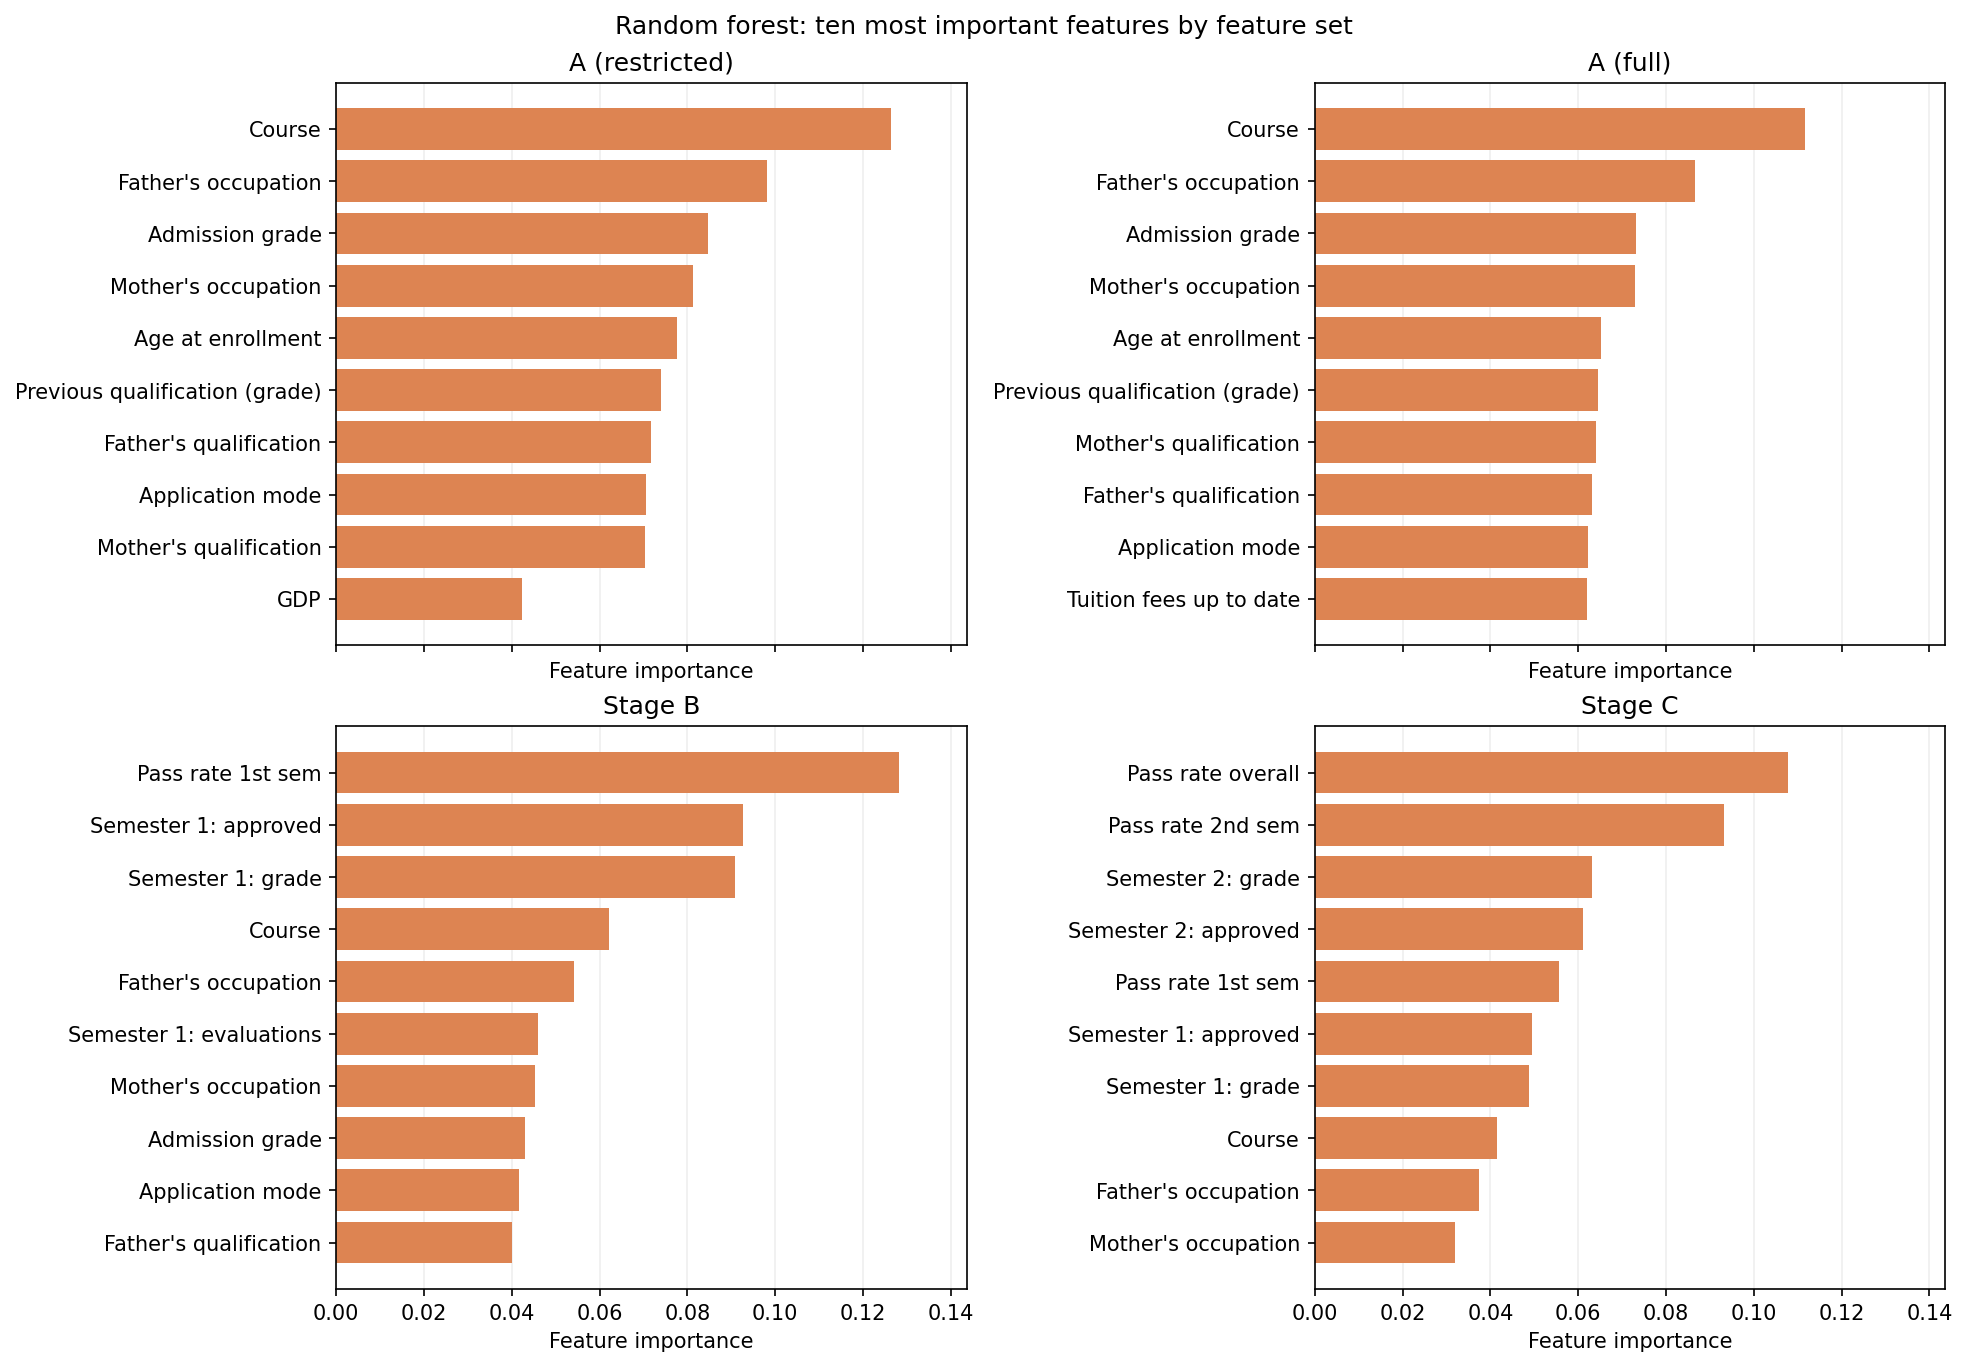

In [ ]:
def grouped_importance(fitted):
    prep = fitted.named_steps["prep"]
    scores = fitted.named_steps["classify"].feature_importances_
    totals = {}
    for name, transformer, columns in prep.transformers_:
        if name == "remainder" or not len(columns):
            continue
        block = scores[prep.output_indices_[name]]
        if name == "one_hot":
            # Each encoded column starts with its original field name.
            encoded = transformer.get_feature_names_out(columns)
            for col in columns:
                totals[col] = block[[label.startswith(col + "_") for label in encoded]].sum()
        else:
            totals.update(zip(columns, block))
    result = pd.Series(totals, dtype=float)
    assert np.isclose(result.sum(), 1)
    return result.sort_values(ascending=False)

importance = {
    stage: grouped_importance(stage_models[("Random forest", stage)])
    for stage in FEATURE_SETS
}

def short_name(name):
    return (name.replace("Curricular units 1st sem (", "Semester 1: ")
                .replace("Curricular units 2nd sem (", "Semester 2: ")
                .replace(")", "")) if name.startswith("Curricular units") and "(" in name else name

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, layout="constrained")
limit = max(values.max() for values in importance.values()) * 1.12
for ax, (stage, values) in zip(axes.flat, importance.items()):
    top = values.head(10).sort_values()
    ax.barh([short_name(name) for name in top.index], top.values, color="#DD8452")
    ax.set_title(stage if stage.startswith("A") else f"Stage {stage}")
    ax.set_xlim(0, limit)
    ax.set_xlabel("Feature importance")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Random forest: ten most important features by feature set")
plt.show()

**A (restricted) vs. A (full).** Course, father's occupation, and admission grade are the three most important features in both enrolment models. Including the financial fields does not substantially change the highest-ranked features, although tuition payment status becomes one of the ten most important features. These results suggest that academic background, program of study, and socioeconomic circumstances provide useful information for predicting outcomes at enrolment.

**A (full) vs. B.** After the first semester, pass rate, approved units, and average grade become the three most important predictors. The relative importance of enrolment features decreases as academic performance becomes available. This shift is consistent with the substantial improvement in predictive performance observed in Section 7.1 and highlights the potential value of monitoring first-semester performance for early intervention.

**B vs. C.** After the second semester, overall pass rate, second-semester pass rate, and second-semester average grade become the three most important predictors. First-semester performance indicators remain among the ten most important features, although their relative importance decreases. Academic performance therefore remains central to prediction, with second-semester results providing additional information.

**Relevance to early intervention.** The results identify different predictive indicators as students progress through their studies. Enrolment features may inform initial risk identification, while semester performance provides opportunities to reassess risk based on academic progress. Feature importance indicates predictive relevance rather than causality.

## 8. Reflection

### 8.1 Key findings and practical implications

### 8.2 Limitations

### 8.3 Ethical and equity considerations

### 8.4 Future work